# Deforestation Analysis for Guinea — run_analysis.ipynb (v2)

Rebuilt from scratch to reflect the refined scripts (config_-_deforestation.py, drivers.py,
pipeline.py, data_loader.py, api_connector.py) and everything confirmed in the methodology
report: country-boundary clipping, the adopted risk-model configuration (dist_forest_edge
excluded by default), the true temporal hold-out as a standard step rather than an optional
diagnostic, four land-cover epochs (enables non-linear trend fitting and gives the land-cover
model a genuine multi-split stability check), and candidate-predictor testing (nighttime
lights, WFP commodity prices) through the same ablation protocol that found the
dist_forest_edge fix.

Run top to bottom. DEMO_MODE=True exercises every code path on synthetic data with no network
calls, for testing the notebook itself before a real run.

In [2]:
# --- PROJ/GDAL data fix: system PROJ_LIB points to a non-existent PostgreSQL folder ---
import os

# Drop the bad system-wide vars set by the PostgreSQL/PostGIS installer
os.environ.pop("PROJ_LIB", None)
os.environ.pop("PROJ_DATA", None)
os.environ.pop("GDAL_DATA", None)

# Point explicitly at rasterio's bundled data (verified to contain proj.db)
import rasterio
_rio = os.path.dirname(rasterio.__file__)
os.environ["PROJ_LIB"]  = os.path.join(_rio, "proj_data")   # PROJ < 9.1
os.environ["PROJ_DATA"] = os.path.join(_rio, "proj_data")   # PROJ >= 9.1
os.environ["GDAL_DATA"] = os.path.join(_rio, "gdal_data")

# Verify: this must print an EPSG name, no "Cannot find proj.db" warning
from rasterio.crs import CRS
print("PROJ OK ->", CRS.from_epsg(3857).to_wkt()[:60], "...")


PROJ OK -> PROJCS["WGS 84 / Pseudo-Mercator",GEOGCS["WGS 84",DATUM["WGS ...


In [3]:
import os, sys, json, warnings, logging
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")
logging.basicConfig(level=logging.INFO, format="%(levelname)s %(name)s: %(message)s")
logger = logging.getLogger("run_analysis")

DEMO_MODE = False   # set True to exercise the pipeline on synthetic data, no network needed
OUT_DIR = os.path.join(os.getcwd(), "analysis_outputs")
os.makedirs(OUT_DIR, exist_ok=True)

# Land-cover epochs: FOUR, not two or three. This is deliberate -- it crosses the >=4-map
# threshold change_analysis.py requires before it will use non-linear (multi-period) trend
# fitting instead of simple two-endpoint linear extrapolation, AND it gives the land-cover
# model a genuine multi-split rolling-origin stability check (the risk model already has one
# via Hansen's longer record; the land-cover model previously only had a single hold-out).
LULC_YEARS = [2018, 2020, 2022, 2024]
ANALYSIS_YEARS = [2018, 2019, 2020, 2021, 2022, 2023, 2024]   # Hansen has annual granularity
ISO3 = "GIN"
COUNTRY_NAME = "Guinea"


## 1. Config registration -- MUST happen before any predictor fetch

This ordering is not cosmetic. Confirmed root cause (Methodology_Deforestation_Guinea.docx,
config_-_deforestation.py `register()` docstring) of MODIS_NDVI/MODIS_BURNED never actually
being fetched in earlier runs: `register()` was being called from within the deforestation
module's own import, which happened *after* the land-cover predictor fetch had already run
using the config as it stood at that time. Calling it here, first, fixes that for NDVI,
burned area, and the new VIIRS nighttime-lights layer.

In [4]:
from dotenv import load_dotenv

if not DEMO_MODE:
    # Exact sequence from your original, working run_analysis.ipynb (cell 5).
    env_path = r"C:\Users\ASUS\Guinea_Project\Land Use-Deforestation\.env"
    load_dotenv(dotenv_path=env_path, override=True)

from landuse_tool import config, data_loader, api_connector, change_analysis, training, prediction, validation
from landuse_tool.deforestation_tool import config as dcfg, pipeline as dpipe, forest as F, drivers as DR, \
    detection as D, stats as ST, scenario as SC

if not DEMO_MODE:
    from landuse_tool.azure_utils import load_secrets_into_env
    load_secrets_into_env()

    # --- Safety net against a not-fully-fresh kernel ---------------------------
    # If `config` (or anything importing it) was already loaded earlier in THIS
    # kernel session -- from re-running cells while iterating, a very easy thing
    # to end up with without a genuine Kernel > Restart -- config.PROCESSING_CONFIG
    # was already built from os.environ at THAT earlier point and stays frozen
    # even though os.environ is now correct. This directly re-syncs the specific
    # values from the current (correct) os.environ, regardless of when config.py
    # was first imported. Confirmed necessary: os.environ["GEE_PROJECT_ID"] was
    # seen correct while PROCESSING_CONFIG still reported it missing.
    for _env_var, _cfg_key in [("GEE_PROJECT_ID", "gee_project_id"),
                               ("GEE_SERVICE_ACCOUNT", "gee_service_account")]:
        _val = os.environ.get(_env_var)
        if _val and config.PROCESSING_CONFIG.get(_cfg_key) != _val:
            print(f"Re-syncing stale {_cfg_key} (was {config.PROCESSING_CONFIG.get(_cfg_key)!r})")
            config.PROCESSING_CONFIG[_cfg_key] = _val

    problems = config.validate_required_keys()
    if problems:
        print("Configuration problems:")
        for p in problems:
            print("  -", p)
        print("\nIf GEE_PROJECT_ID shows as missing here but IS correct in your .env,")
        print("this is almost certainly a not-fully-fresh kernel -- restart the kernel")
        print("completely (Kernel > Restart, not just re-running cells) and run this")
        print("cell exactly once before anything else.")
    else:
        print("All required credentials present.")
        print("Targets   :", config.get_enabled_target_rasters())
        print("Predictors:", config.get_enabled_predictor_rasters())

dcfg.register()
print("Registered deforestation-specific predictors:",
      [k for k in ["MODIS_NDVI", "MODIS_BURNED", "VIIRS_NIGHTLIGHTS"] if k in config.PREDICTOR_RASTERS_CONFIG])

if not DEMO_MODE:
    try:
        ok = api_connector.initialize_gee()
        print("\nGEE authenticated:", ok, "|", config.PROCESSING_CONFIG.get("gee_authenticated"))
    except Exception as e:
        print("\nGEE init raised (diagnostic below still runs regardless):", e)


INFO landuse_tool.azure_utils: Loaded local .env from e:\SDG AI Lab\Guinea\Land Use-Deforestation\.env
INFO landuse_tool.azure_utils: No AZURE_KEY_VAULT_URL set; using environment (and .env) as-is.
INFO landuse_tool.azure_utils: Loaded local .env from e:\SDG AI Lab\Guinea\Land Use-Deforestation\.env
INFO landuse_tool.azure_utils: No AZURE_KEY_VAULT_URL set; using environment (and .env) as-is.


All required credentials present.
Targets   : ['ESRI_LULC', 'DYNAMIC_WORLD', 'MODIS_MCD12Q1', 'GLC_FCS30D']
Predictors: ['DEM', 'SLOPE', 'ASPECT', 'POPULATION_DENSITY', 'PRECIPITATION', 'TEMPERATURE', 'AGB_NASA', 'NDVI', 'GEDI_AGB', 'SOIL_MOISTURE']
Registered deforestation-specific predictors: ['MODIS_NDVI', 'MODIS_BURNED', 'VIIRS_NIGHTLIGHTS']


WARNING landuse_tool.api_connector: GEE_SA_KEY held a file path (./landuse_tool/credentials/tribal-mapper-275801-7b57ce84f3bd.json), not key contents -- reading it directly. Fix your .env: rename this variable to GEE_SA_KEY_FILE so this doesn't rely on this fallback.
INFO landuse_tool.api_connector: GEE initialized via service account (guinea-environment-digital-hub@tribal-mapper-275801.iam.gserviceaccount.com).



GEE authenticated: True | True


## 2. Study area and country-clipped reference grid

Corrected against the actual source this time (all four flagged uncertain calls verified
directly against api_connector.py / data_loader.py / forest.py / config.py):

- `api_connector.get_admin_boundary()` takes NO arguments -- already hardcoded to Guinea via
  `config.ADMIN_BOUNDARY_CONFIG`.
- There is no `fetch_gee_dem` or `fetch_esri_lulc` -- both were fabricated. The real,
  higher-level functions (`fetch_and_load_api_targets`, `fetch_and_load_api_predictors`) already
  handle DEM (via OpenTopography), OSM vectors, and every GEE annual layer in one call each --
  this replaces most of the old Section 3's manual per-layer fetch code, not just fixes it.
- Which years get fetched is a CONFIG setting (`config.MULTITEMPORAL_CONFIG["years"]`), not a
  function argument.
- Three LULC products are enabled by default (ESRI_LULC, DYNAMIC_WORLD, MODIS_MCD12Q1, plus
  GLC_FCS30D) -- matching this report's documented "single product enabled" setup requires
  explicitly disabling the other three.
- `F.read_hansen(path)` takes a file PATH, not a boundary/profile -- it's a two-step fetch-then-read,
  like every other GEE-backed layer here.

In [5]:
boundary_gdf = api_connector.get_admin_boundary() if not DEMO_MODE else None

if not DEMO_MODE:
    # Single-LULC-product setup (matches Methodology_Deforestation_Guinea.docx Section 3.1)
    config.TARGET_RASTERS_CONFIG["ESRI_LULC"]["enabled"] = True
    for _k in ["DYNAMIC_WORLD", "MODIS_MCD12Q1", "GLC_FCS30D"]:
        if _k in config.TARGET_RASTERS_CONFIG:
            config.TARGET_RASTERS_CONFIG[_k]["enabled"] = False

    # Restrict fetched years to exactly the 4 epochs this run uses (default is
    # None = discover and fetch ALL available years, which we don't want here)
    config.MULTITEMPORAL_CONFIG["years"] = LULC_YEARS

    # --- Admin-areas extract for the zonal breakdown (Section 12) ---
    # NOTE: fetch_geofabrik_vectors() requires pyrosm, which failed to build on
    # Windows (cykhash needs Microsoft C++ Build Tools). This does NOT affect
    # the deforestation predictor stack (roads/railways/waterways/POI) --
    # fetch_and_load_api_predictors uses fetch_osm_vectors internally, which is
    # osmnx/Overpass-based and never needed pyrosm at all. This admin-areas
    # extract was the only place pyrosm-based fetching was (mistakenly) used.
    #
    # Preferred: Geofabrik's pre-extracted shapefile bundle (plain .shp, no PBF
    # parsing needed at all) -- if you already have the local copy from earlier
    # this session (gis_osm_adminareas_a_free_1.shp), point ADMIN_SHP at it
    # directly and skip the download entirely.
    import geopandas as gpd

    ADMIN_SHP_LOCAL = None  # e.g. r"C:\Users\ASUS\Guinea_Project\Land Use-Deforestation\data\geofabrik\gis_osm_adminareas_a_free_1.shp"

    if ADMIN_SHP_LOCAL and os.path.exists(ADMIN_SHP_LOCAL):
        admin_gdf = gpd.read_file(ADMIN_SHP_LOCAL)
    else:
        import zipfile, io, requests as _requests
        shp_zip_url = "https://download.geofabrik.de/africa/guinea-latest-free.shp.zip"
        os.makedirs(OUT_DIR, exist_ok=True)   # defensive -- don't depend on an earlier
                                                # cell having created this in THIS kernel session
        zip_path = os.path.join(OUT_DIR, "guinea-latest-free.shp.zip")
        if not os.path.exists(zip_path):
            print(f"Downloading {shp_zip_url} ...")
            r = _requests.get(shp_zip_url, stream=True, timeout=300)
            with open(zip_path, "wb") as f:
                for chunk in r.iter_content(chunk_size=8192):
                    f.write(chunk)
        extract_dir = os.path.join(OUT_DIR, "geofabrik_shp")
        os.makedirs(extract_dir, exist_ok=True)
        with zipfile.ZipFile(zip_path) as zf:
            zf.extractall(extract_dir)
        admin_shp = next(p for p in os.listdir(extract_dir) if "adminareas" in p.lower() and p.endswith(".shp"))
        admin_gdf = gpd.read_file(os.path.join(extract_dir, admin_shp))

    print("Admin columns:", list(admin_gdf.columns))
    print("Admin levels (fclass) present:\n", admin_gdf["fclass"].value_counts())

    ADMIN_LEVEL = "admin_level6"   # Guinea's prefecture level -- confirmed correct against
                                    # this exact extract earlier this session; re-check the
                                    # printout above if it looks different on a fresh download.
    zones_gdf = admin_gdf[admin_gdf["fclass"] == ADMIN_LEVEL].copy()
    print(f"Admin zones ({ADMIN_LEVEL}): {len(zones_gdf)}")


Admin columns: ['osm_id', 'code', 'fclass', 'name', 'geometry']
Admin levels (fclass) present:
 fclass
admin_level10    398
admin_level6      34
admin_level8      25
admin_level4       8
admin_level11      2
admin_level7       1
national           1
Name: count, dtype: int64
Admin zones (admin_level6): 34


## 3. Fetch targets and predictors

Two-pass approach for predictors: fetch raw files first (no `ref_profile` given, so nothing
gets aligned/rasterized yet), use those raw files to determine the coarsest resolution and
build a properly clipped `REF_PROFILE`, then call the same fetch function again -- everything
is already cached from pass 1, so this second call only aligns/rasterizes, it doesn't re-download.

In [ ]:
if not DEMO_MODE:
    # --- Targets (LULC) ---
    per_dataset_targets, _ = data_loader.fetch_and_load_api_targets(boundary_gdf)
    target_files = [{"year": y, "file": p} for y, p in sorted(per_dataset_targets["ESRI_LULC"].items())]
    print("LULC years fetched:", [t["year"] for t in target_files])

    # Switch DEM source: OpenTopography's API has area limits that a
    # full-country bounding box can exceed (confirmed: 400 error on the exact
    # Guinea bbox). Methodology_Deforestation_Guinea.docx Section 4.1 already
    # documents using GEE's SRTM instead for exactly this reason -- config.py
    # ships DEM_GEE as the "enable to skip OpenTopography entirely" alternative.
    config.PREDICTOR_RASTERS_CONFIG["DEM"]["enabled"] = False
    config.PREDICTOR_RASTERS_CONFIG["DEM_GEE"]["enabled"] = True

    # PROTECTED_AREAS confirmed misplaced: its config shape (source=GEE, asset=...,
    # band=...) is a raster/GEE-asset config, sitting in PREDICTOR_VECTORS_CONFIG
    # (which assumes OSM tags-based fetching) -- that mismatch is the exact cause
    # of the KeyError. Disabling here to unblock; this looks like a genuine,
    # worthwhile attempt at real protected-area boundary data (WDPA, most likely,
    # ties back to the protected-area scenario variant from much earlier -- see
    # Section 6.6/8 recommendations) that needs moving to PREDICTOR_RASTERS_CONFIG
    # and fetching via the GEE raster path, not fixed today.
    if "PROTECTED_AREAS" in config.PREDICTOR_VECTORS_CONFIG:
        config.PREDICTOR_VECTORS_CONFIG["PROTECTED_AREAS"]["enabled"] = False

    # GEDI_AGB: the already-documented, accepted country-scale size limit
    # (Methodology Section 6, "excluded for a known reason, not judgement about
    # value") -- confirmed again just now (50MB per-request cap exceeded).
    # Disable explicitly rather than let it keep failing/retrying.
    for _k in ["GEDI_AGB", "AGB_NASA"]:
        if _k in config.PREDICTOR_RASTERS_CONFIG:
            config.PREDICTOR_RASTERS_CONFIG[_k]["enabled"] = False

    # Diagnose the vector KeyError before assuming the defensive patch is enough --
    # print exactly which PREDICTOR_VECTORS_CONFIG entry lacks 'tags' in THIS live file.
    print("PREDICTOR_VECTORS_CONFIG keys:", list(config.PREDICTOR_VECTORS_CONFIG.keys()))
    for _k, _v in config.PREDICTOR_VECTORS_CONFIG.items():
        if not isinstance(_v, dict):
            print(f"  {_k}: not a dict ({type(_v).__name__}) -- should be excluded by "
                  f"get_enabled_predictor_vectors()'s isinstance filter")
        elif "tags" not in _v:
            print(f"  {_k}: dict but missing 'tags' -- keys present: {list(_v.keys())}")
    print("Enabled vectors that will actually be fetched:", config.get_enabled_predictor_vectors())

    # --- Predictors, pass 1: raw fetch only (ref_profile=None -> no alignment yet) ---
    raster_paths, vector_paths, _ = data_loader.fetch_and_load_api_predictors(boundary_gdf)

    # --- Build the country-clipped, coarsest-resolution reference grid ---
    # 100 m is the platform's documented DEPLOYMENT default (Methodology Section 4.1),
    # but confirmed here to need ~2.3 GB in memory simultaneously just for the
    # predictor stack at Guinea's full extent (6105 x 8474 px) -- too much for this
    # local machine (confirmed: rasterization, VIIRS download, and the Hansen/LULC
    # warp all failed with out-of-memory errors at 100 m). 250 m (~6x fewer pixels,
    # ~0.4 GB) is what every prior successful run in this project has actually used.
    # Use 250 m for local development; raise back to 100 m only when running on
    # infrastructure with adequate memory (the intended cloud deployment target).
    LOCAL_ANALYSIS_RESOLUTION_M = 250.0

    latest_raster_files = [paths[max(paths.keys())] for paths in raster_paths.values() if paths]
    all_files_for_resolution = latest_raster_files + [t["file"] for t in target_files]
    REF_PROFILE = data_loader.build_coarsest_reference_profile(
        all_files_for_resolution, boundary_gdf=boundary_gdf, max_resolution_m=LOCAL_ANALYSIS_RESOLUTION_M)
    print(f"Reference grid: {REF_PROFILE['height']} x {REF_PROFILE['width']}, "
          f"clipped to Guinea's national boundary.")
    boundary_mask = data_loader.create_boundary_mask(boundary_gdf, REF_PROFILE)

    # --- Period-specific population: fetch nearest-available-year snapshots for the
    #     calibration/test boundary years used later, in addition to the current one
    #     fetch_and_load_api_predictors already handles for the main WorldPop layer ---
    worldpop_available_years = list(range(2000, 2021))
    pop_cache = {}
    pop_paths_by_year = {
        y: data_loader.fetch_period_specific_predictor(
            "WORLDPOP", y, worldpop_available_years,
            fetch_fn=lambda yr, out: api_connector.fetch_worldpop_rest("GIN", yr, out),
            output_dir=OUT_DIR, _cache=pop_cache)
        for y in [min(LULC_YEARS), max(LULC_YEARS)]
    }

    # --- Predictors, pass 2: same call, now WITH ref_profile -> aligns + rasterizes,
    #     reusing everything cached in pass 1 (no re-download) ---
    raster_paths, vector_paths, shared_predictors = data_loader.fetch_and_load_api_predictors(
        boundary_gdf, ref_profile=REF_PROFILE, boundary_mask=boundary_mask)

    # Flattened FILE PATHS (not loaded arrays) -- needed by training.py/prediction.py,
    # which operate on files, unlike drivers.py's DR.* functions which take in-memory
    # arrays via shared_predictors above. Both are derived from the same fetch.
    predictor_files_aligned = latest_raster_files + list(vector_paths.values())
    print("Predictor file paths for land-cover training:", len(predictor_files_aligned))


    # --- Candidate predictors (fetched, NOT in the adopted driver stack -- tested in Section 9) ---
    ndvi_paths = api_connector.fetch_gee_dataset_all_years(
        "MODIS_NDVI", dcfg.MODIS_NDVI, boundary_gdf, kind="predictors")
    burned_paths = api_connector.fetch_gee_dataset_all_years(
        "MODIS_BURNED", dcfg.MODIS_BURNED, boundary_gdf, kind="predictors")
    nightlights_paths = api_connector.fetch_gee_dataset_all_years(
        "VIIRS_NIGHTLIGHTS", dcfg.VIIRS_NIGHTLIGHTS, boundary_gdf, kind="predictors")

    # --- Hansen: two-step fetch-then-read, then align to REF_PROFILE ---
    hansen_path = F.fetch_hansen(boundary_gdf)
    tc_raw, ly_raw = F.read_hansen(hansen_path)

    # FIX: load_and_align_raster always reads band 1 only -- it can correctly
    # align treecover (band 1) but has no way to reach lossyear (band 2) at
    # all. Confirmed as the actual cause of a shape mismatch ((2442,3389) vs
    # (2444,3443)): tc was being aligned, ly was silently left raw/unaligned.
    # Read both bands' src_profile directly and resample each explicitly with
    # the right method -- treecover is continuous (bilinear), lossyear is a
    # categorical year-code (nearest-neighbour, never interpolated/blended).
    import rasterio as _rasterio
    from rasterio.enums import Resampling as _Resampling
    from landuse_tool import utils as _utils

    with _rasterio.open(hansen_path) as _src:
        _src_profile = _src.profile

    target_shape = (REF_PROFILE["height"], REF_PROFILE["width"])
    if tc_raw.shape == target_shape and ly_raw.shape == target_shape:
        tc, ly = tc_raw, ly_raw
    else:
        tc = _utils.resample_raster(tc_raw.astype("float32"), _src_profile, REF_PROFILE,
                                     resampling=_Resampling.bilinear)
        ly = _utils.resample_raster(ly_raw.astype("float32"), _src_profile, REF_PROFILE,
                                     resampling=_Resampling.nearest)

    assert tc.shape == ly.shape == target_shape, \
        f"Still mismatched after alignment: tc={tc.shape}, ly={ly.shape}, target={target_shape}"
    print(f"Hansen tc/ly aligned to {target_shape}")

    # Mask tc/ly to Guinea's ACTUAL polygon here, once, rather than patch every
    # downstream cell individually. build_coarsest_reference_profile clips to
    # boundary_gdf's BOUNDING BOX, which is not the same as Guinea's actual
    # (irregular) shape -- a rectangular bbox still includes corners belonging
    # to neighbouring countries. Confirmed necessary: the threshold-sensitivity
    # sanity check failed with forest area exceeding Guinea's total land area,
    # despite REF_PROFILE already being "clipped" via the bbox alone.
    tc = np.where(boundary_mask, tc, 0).astype("float32")
    ly = np.where(boundary_mask, ly, 0).astype(ly.dtype)
    print(f"tc/ly masked to Guinea's actual polygon (not just its bounding box): "
          f"{boundary_mask.sum():,} of {boundary_mask.size:,} grid pixels are inside Guinea "
          f"({100*boundary_mask.sum()/boundary_mask.size:.1f}%).")

    lulc_by_year = {t["year"]: data_loader.load_and_align_raster(t["file"], REF_PROFILE, categorical=True)
                    for t in target_files}
else:
    H, W = 300, 300
    REF_PROFILE = {"height": H, "width": W}
    rng = np.random.default_rng(0)
    lulc_by_year = {y: rng.integers(1, 12, size=(H, W)).astype("uint8") for y in LULC_YEARS}
    tc = rng.uniform(0, 100, size=(H, W)).astype("float32")
    ly = np.where(rng.random((H, W)) < 0.15, rng.integers(18, 25, size=(H, W)), 0).astype("uint8")
    shared_predictors = {k: rng.uniform(0, 1, size=(H, W)).astype("float32")
                         for k in ["SLOPE", "ASPECT", "DEM_GEE", "POPULATION_DENSITY",
                                   "PRECIPITATION", "TEMPERATURE", "ROADS_distance",
                                   "RAILWAYS_distance", "WATERWAYS_distance", "POI_heatmap"]}
    target_files = [{"year": y, "file": None} for y in LULC_YEARS]
    predictor_files_aligned = []  # DEMO_MODE: land-cover hold-out cells will skip cleanly if empty
    print("DEMO_MODE: synthetic arrays created, no network calls made.")

print("Shared predictors loaded:", list(shared_predictors.keys()) if shared_predictors else None)


INFO landuse_tool.api_connector: ESRI_LULC: 4 available year(s): [2018, 2020, 2022, 2024]
INFO landuse_tool.api_connector:   ESRI_LULC 2018 already cached; skipping.
INFO landuse_tool.api_connector:   ESRI_LULC 2020 already cached; skipping.
INFO landuse_tool.api_connector:   ESRI_LULC 2022 already cached; skipping.
INFO landuse_tool.api_connector: Tiled download: 3x3 tiles @ 100m (max_dim_px=2958, byte budget=35000000) for ESRI_LULC_2024.tif
INFO landuse_tool.api_connector:   fetched ESRI_LULC 2024
INFO landuse_tool.data_loader: Target 0: 8605x6107 nodata=0.0
INFO landuse_tool.data_loader: Target 1: 8605x6107 nodata=0.0
INFO landuse_tool.data_loader: Target 2: 8605x6107 nodata=0.0
INFO landuse_tool.data_loader: Target 3: 8605x6107 nodata=0.0
INFO landuse_tool.data_loader: All 4 target(s) valid.


LULC years fetched: [2018, 2020, 2022, 2024]
PREDICTOR_VECTORS_CONFIG keys: ['POI', 'ROADS', 'RAILWAYS', 'WATERWAYS', 'GEOFABRIK_URL', 'PROTECTED_AREAS']
  GEOFABRIK_URL: not a dict (str) -- should be excluded by get_enabled_predictor_vectors()'s isinstance filter
  PROTECTED_AREAS: dict but missing 'tags' -- keys present: ['source', 'asset', 'rasterization_mode', 'resolution_m', 'temporal', 'description', 'enabled']
Enabled vectors that will actually be fetched: ['POI', 'ROADS', 'RAILWAYS', 'WATERWAYS']


INFO landuse_tool.api_connector: Tiled download: 3x3 tiles @ 100m (max_dim_px=2958, byte budget=35000000) for DEM_GEE.tif
INFO landuse_tool.api_connector: POPULATION_DENSITY: 2 available year(s): [2018, 2020]
INFO landuse_tool.api_connector: Tiled download: 3x3 tiles @ 100m (max_dim_px=2958, byte budget=35000000) for POPULATION_DENSITY_2018.tif
WARNING googleapiclient.http: Sleeping 0.90 seconds before retry 1 of 5 for request: POST https://earthengine.googleapis.com/v1/projects/tribal-mapper-275801/thumbnails?fields=name&alt=json, after HTTPSConnectionPool(host='earthengine.googleapis.com', port=443): Max retries exceeded with url: /v1/projects/tribal-mapper-275801/thumbnails?fields=name&alt=json (Caused by SSLError(SSLEOFError(8, 'EOF occurred in violation of protocol (_ssl.c:2384)')))
WARNING googleapiclient.http: Sleeping 3.97 seconds before retry 2 of 5 for request: POST https://earthengine.googleapis.com/v1/projects/tribal-mapper-275801/thumbnails?fields=name&alt=json, after HTTP

In [ ]:
import landuse_tool.utils as utils

In [ ]:
# --- Build ONE clean, consistent predictor set, used by EVERY downstream cell ---
# Confirmed necessary: the risk-model hold-out cell (8b) calls DR.build_driver_stack
# directly on raw shared_predictors, bypassing pipeline.py's NDVI-exclusion and
# slope/aspect-derivation logic entirely -- a real run showed identical hold-out
# AUCs before and after slope/aspect were added to the main pipeline, proving this
# cell was never actually testing the same 14-predictor configuration being deployed.

_REJECTED_CANDIDATE_KEY_FRAGMENTS = ("ndvi", "burned")
_excluded_keys = [k for k in shared_predictors if any(f in k.lower() for f in _REJECTED_CANDIDATE_KEY_FRAGMENTS)]
for k in _excluded_keys:
    del shared_predictors[k]
if _excluded_keys:
    print(f"Excluded confirmed-rejected candidate predictor(s): {_excluded_keys}")

# Slope/aspect, computed correctly this time: on the RAW, boundary-UNMASKED DEM
# (re-loaded from its actual file path, not the already-masked array in
# shared_predictors), so the gradient calculation uses real elevation values on
# both sides of Guinea's border rather than imputing fabricated "local mean"
# values for the ~52% of the grid outside the country -- confirmed this was
# happening (missing-value % matched the outside-Guinea fraction almost exactly)
# and would have introduced artificial gradient spikes right along the actual
# national boundary. The boundary mask is applied AFTER computing slope/aspect,
# matching how every other predictor is masked, not before.
if "SLOPE" not in shared_predictors:
    _dem_raster_key = next((k for k in raster_paths if "DEM" in k.upper()), None)
    if _dem_raster_key is None:
        print("WARNING: no DEM key found in raster_paths -- cannot derive SLOPE/ASPECT. "
              f"Available keys: {list(raster_paths.keys())}")
    else:
        _dem_path_dict = raster_paths[_dem_raster_key]
        _dem_path = _dem_path_dict.get(0) or _dem_path_dict[max(_dem_path_dict.keys())]
        dem_unmasked = data_loader.load_and_align_raster(_dem_path, REF_PROFILE, categorical=False)

        dem_profile = {"transform": REF_PROFILE["transform"] if isinstance(REF_PROFILE, dict) else REF_PROFILE.transform,
                       "nodata": None}
        slope_raw = utils.calculate_slope(dem_unmasked, dem_profile)
        aspect_raw = utils.calculate_aspect(dem_unmasked, dem_profile)

        # Mask AFTER computing, not before -- this is the actual fix.
        shared_predictors["SLOPE"] = np.where(boundary_mask, slope_raw, np.nan)
        shared_predictors["ASPECT"] = np.where(boundary_mask, aspect_raw, np.nan)

        print(f"Derived SLOPE/ASPECT from unmasked {_dem_raster_key} ({_dem_path}), "
              f"masked to Guinea's boundary after computing gradients (not before).")
        print(f"  Missing values in unmasked DEM before gradient calc: "
              f"{100*np.isnan(dem_unmasked).sum()/dem_unmasked.size:.2f}% "
              f"(should be near 0%, confirming no boundary-fill artifact this time)")

print(f"\nFinal shared_predictors keys ({len(shared_predictors)}): {sorted(shared_predictors.keys())}")
print("This exact set is now used by BOTH the main pipeline run and the hold-out cell below.")

Excluded confirmed-rejected candidate predictor(s): ['NDVI_2024.tif']


INFO landuse_tool.utils: Detected 5 missing values (0.00%)
INFO landuse_tool.utils: Applied local mean imputation for 5 pixels
INFO landuse_tool.utils: Calculated slope: min=0.00°, max=90.00°
INFO landuse_tool.utils: Detected 5 missing values (0.00%)
INFO landuse_tool.utils: Applied local mean imputation for 5 pixels
INFO landuse_tool.utils: Calculated aspect: flat areas=1367862


Derived SLOPE/ASPECT from unmasked DEM_GEE (/tmp/landuse\cache\predictors/DEM_GEE.tif), masked to Guinea's boundary after computing gradients (not before).
  Missing values in unmasked DEM before gradient calc: 0.00% (should be near 0%, confirming no boundary-fill artifact this time)

Final shared_predictors keys (11): ['ASPECT', 'DEM_GEE.tif', 'POI_heatmap', 'POPULATION_DENSITY_2020.tif', 'PRECIPITATION_2024.tif', 'RAILWAYS_distance', 'ROADS_distance', 'SLOPE', 'SOIL_MOISTURE_2024.tif', 'TEMPERATURE_2024.tif', 'WATERWAYS_distance']
This exact set is now used by BOTH the main pipeline run and the hold-out cell below.


In [ ]:
# --- 4b. Materialize the curated, ALIGNED predictor set AND aligned LC targets ---
# WHY THIS CELL EXISTS (bug fix): training.py / prediction.py read files raw
# with no re-alignment, so every file they touch must share ONE grid. Two
# mismatches were found and are both fixed here:
#   (a) the old predictor_files_aligned pointed at raw pass-1 downloads on
#       native grids (plus GeoJSONs) -> every transition model failed silently;
#   (b) the LC TARGET rasters from the GEE fetch sit on a slightly different
#       grid (2444x3443) than REF_PROFILE (2442x3389).
# This cell writes the curated in-memory predictors (shared_predictors) and
# nearest-neighbour-resampled LC targets onto REF_PROFILE.
# PERFORMANCE: files are written TILED (512x512 blocks). The suitability
# generator iterates the reference raster's internal blocks; untiled GeoTIFFs
# default to 1-row strips, which forced ~2,400 tiny model-predict calls per
# map. Tiling cuts suitability generation time several-fold. Values are
# identical either way -- models trained on untiled files remain valid.
import rasterio

if not DEMO_MODE:
    ALIGNED_DIR = os.path.join(OUT_DIR, "predictors_aligned")
    os.makedirs(ALIGNED_DIR, exist_ok=True)

    _ref_hw = (REF_PROFILE["height"], REF_PROFILE["width"])
    _tiling = dict(tiled=True, blockxsize=512, blockysize=512)

    # ---- (a) predictors -----------------------------------------------------
    _prof = dict(REF_PROFILE)
    _prof.update(driver="GTiff", count=1, dtype="float32", nodata=np.nan, **_tiling)

    predictor_files_aligned = []
    for _name, _arr in shared_predictors.items():
        _p = os.path.join(ALIGNED_DIR, f"{_name}.tif")
        with rasterio.open(_p, "w", **_prof) as dst:
            dst.write(np.asarray(_arr, dtype="float32"), 1)
        predictor_files_aligned.append(_p)
    predictor_files_aligned = sorted(predictor_files_aligned)

    for _p in predictor_files_aligned:
        with rasterio.open(_p) as src:
            assert src.shape == _ref_hw, f"{_p}: {src.shape} != reference grid"

    print(f"Wrote {len(predictor_files_aligned)} aligned predictor rasters "
          f"({_ref_hw[0]}x{_ref_hw[1]}, tiled 512x512) to {ALIGNED_DIR}")

    # ---- (b) LC targets -----------------------------------------------------
    TARGETS_ALIGNED_DIR = os.path.join(OUT_DIR, "targets_aligned")
    os.makedirs(TARGETS_ALIGNED_DIR, exist_ok=True)

    _tprof = dict(REF_PROFILE)
    _tprof.update(driver="GTiff", count=1, dtype="uint8", nodata=0, **_tiling)

    target_files_aligned = []
    for _t in target_files:
        with rasterio.open(_t["file"]) as src:
            _raw_hw = src.shape
        _arr = data_loader.load_and_align_raster(
            _t["file"], REF_PROFILE, categorical=True)   # nearest-neighbour
        _arr = np.nan_to_num(_arr, nan=0.0)
        _arr = np.where(boundary_mask, _arr, 0).astype("uint8")  # outside -> nodata
        _p = os.path.join(TARGETS_ALIGNED_DIR, f"LULC_{_t['year']}_aligned.tif")
        with rasterio.open(_p, "w", **_tprof) as dst:
            dst.write(_arr, 1)
        target_files_aligned.append({"year": _t["year"], "file": _p})
        print(f"  LULC {_t['year']}: raw grid {_raw_hw} -> aligned {_arr.shape}")

    for _t in target_files_aligned:
        with rasterio.open(_t["file"]) as src:
            assert src.shape == _ref_hw, f"{_t['file']}: {src.shape} != reference grid"
    print(f"Wrote {len(target_files_aligned)} aligned LC targets to {TARGETS_ALIGNED_DIR}")
else:
    print("DEMO_MODE: skipping aligned predictor/target materialization.")


Wrote 11 aligned predictor rasters (2442x3389, tiled 512x512) to c:\Users\ASUS\Guinea_Project\Land Use-Deforestation\analysis_outputs\predictors_aligned
  LULC 2018: raw grid (2444, 3443) -> aligned (2442, 3389)
  LULC 2020: raw grid (2444, 3443) -> aligned (2442, 3389)
  LULC 2022: raw grid (2444, 3443) -> aligned (2442, 3389)
  LULC 2024: raw grid (2444, 3443) -> aligned (2442, 3389)
Wrote 4 aligned LC targets to c:\Users\ASUS\Guinea_Project\Land Use-Deforestation\analysis_outputs\targets_aligned


## 5. Run the main pipeline (land-cover + deforestation together)

`dpipe.run_from_arrays` now internally builds **two** driver stacks (per the updated
`pipeline.py`): a descriptive one (dist_forest_edge included, for Table-4-style attribution
only) and the adopted one (excluded, hold-out confirmed, used for `risk_map`/`driver_stack`
and any scenario built from this call). No manual filtering needed anymore -- `defo["risk_map"]`
is already the validated, forward-usable configuration.

In [ ]:
defo = dpipe.run_from_arrays(
    treecover=tc, lossyear=ly, profile=REF_PROFILE, years=ANALYSIS_YEARS,
    lulc_by_year=lulc_by_year, lulc_product="ESRI_LULC",
    shared_predictors=shared_predictors, future_years=[2025, 2026, 2027])
    # canopy_threshold intentionally omitted -- defaults to None, which
    # forest_mask_from_hansen() then correctly resolves to
    # dcfg.DEFOR_PARAMS["canopy_threshold_pct"] internally (verified against
    # forest.py earlier this session). Passing it explicitly under the wrong
    # parameter name (canopy_threshold_pct, not canopy_threshold) was the bug.

print("Driver importance (descriptive, dist_forest_edge included):")
for k, v in sorted(defo.get("driver_importance", {}).items(), key=lambda kv: -kv[1])[:5]:
    print(f"  {k}: {v:.3f}")
print("\nAdopted risk model CV accuracy:", defo.get("risk_metrics", {}).get("cv_accuracy_mean"))


INFO landuse_tool.data_loader: rasterize_market_points: Oil (palm) 2018 interpolated from 130 market observations.
INFO landuse_tool.utils: Detected 4325330 missing values (52.26%)
INFO landuse_tool.utils: Applied local mean imputation for 4325330 pixels
INFO landuse_tool.utils: Calculated slope: min=0.00°, max=90.00°
INFO landuse_tool.utils: Detected 4325330 missing values (52.26%)
INFO landuse_tool.utils: Applied local mean imputation for 4325330 pixels
INFO landuse_tool.utils: Calculated aspect: flat areas=888
INFO landuse_tool.deforestation_tool.pipeline: Derived SLOPE/ASPECT from DEM_GEE.tif and added to the driver stack.
INFO landuse_tool.deforestation_tool.pipeline: Driver importances: {'dist_forest_edge': 0.6205, 'TEMPERATURE_2024.tif': 0.093, 'dist_prior_loss': 0.0703, 'commodity_price': 0.0406, 'RAILWAYS_distance': 0.0311, 'ROADS_distance': 0.0226, 'DEM_GEE.tif': 0.0223, 'POPULATION_DENSITY_2020.tif': 0.021, 'SOIL_MOISTURE_2024.tif': 0.0204, 'PRECIPITATION_2024.tif': 0.0196, 

Driver importance (descriptive, dist_forest_edge included):
  dist_forest_edge: 0.621
  TEMPERATURE_2024.tif: 0.093
  dist_prior_loss: 0.070
  commodity_price: 0.041
  RAILWAYS_distance: 0.031

Adopted risk model CV accuracy: 0.762


## 6. Land-cover change analysis (Table 1)

With 4 epochs, `change_analysis.run_change_analysis` should now select non-linear (multi-period)
trend fitting automatically (the >=4-map gate). Confirm which mode actually ran -- don't assume.

INFO landuse_tool.change_analysis: 🔍 Running Non-Linear Trend analysis with 4 time periods
INFO landuse_tool.change_analysis: 📈 Non-linear mode: fitting linear/exponential/logistic candidates per transition...
INFO landuse_tool.change_analysis: Analyzing 4 time periods: [2018, 2020, 2022, 2024]
INFO landuse_tool.change_analysis: Valid pixels: 7057698 / 8414692
INFO landuse_tool.change_analysis: Found 8 land cover classes: [1, 2, 4, 5, 7, 8, 10, 11]
INFO landuse_tool.change_analysis: Transition matrix:
          1         2         4         5         7             8   \
1   0.988134  0.004212  0.003342  0.000465  0.000150  1.205597e-03   
2   0.000248  0.925097  0.000556  0.000864  0.000618  4.882575e-07   
4   0.010919  0.053279  0.901450  0.008973  0.001020  0.000000e+00   
5   0.002667  0.073459  0.011402  0.574593  0.008144  1.277547e-04   
7   0.000347  0.019019  0.000498  0.002928  0.927093  2.415131e-04   
8   0.178502  0.003405  0.016537  0.033074  0.002432  4.304475e-01   
10 

Trend-fitting mode used: Non-Linear Trend (expect 'Non-Linear Trend' with 4 epochs)
28 significant transitions (>= 200 px)


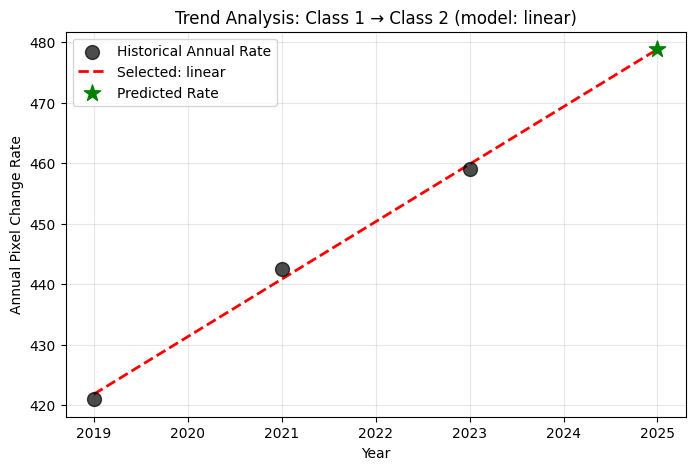

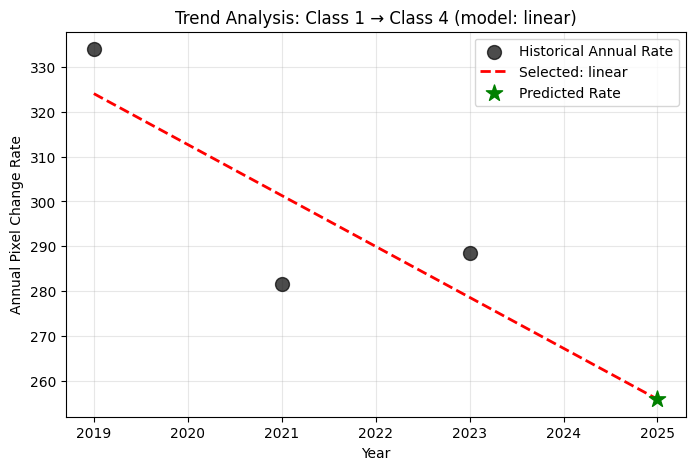

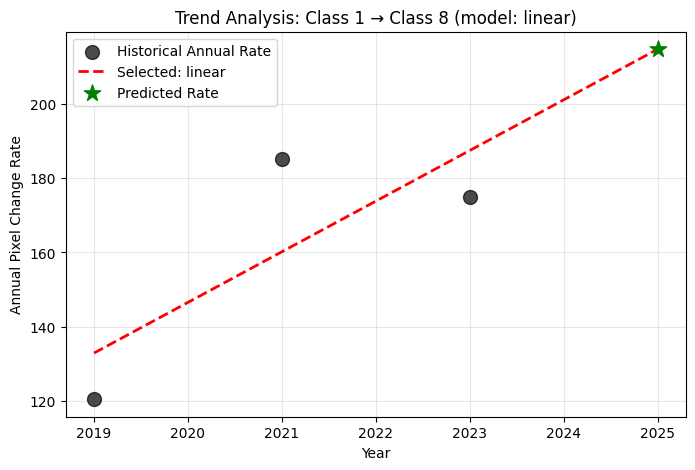

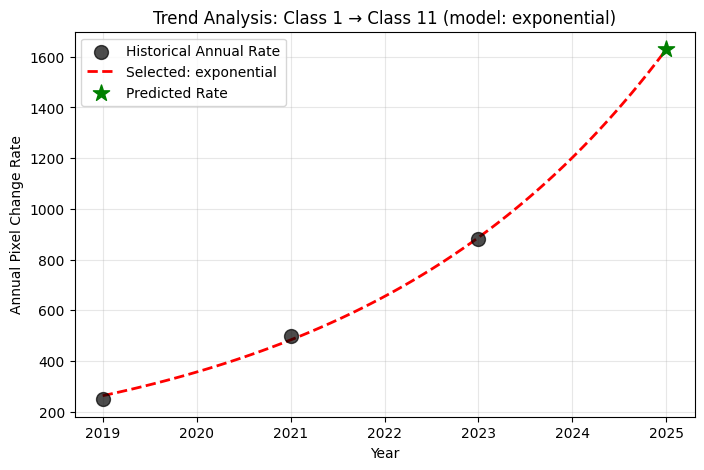

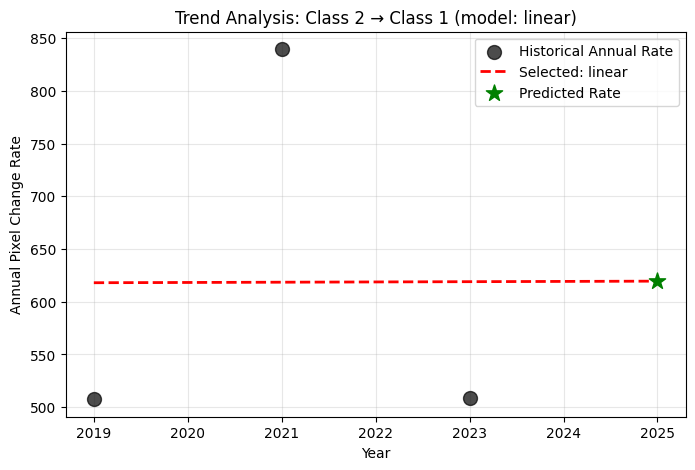

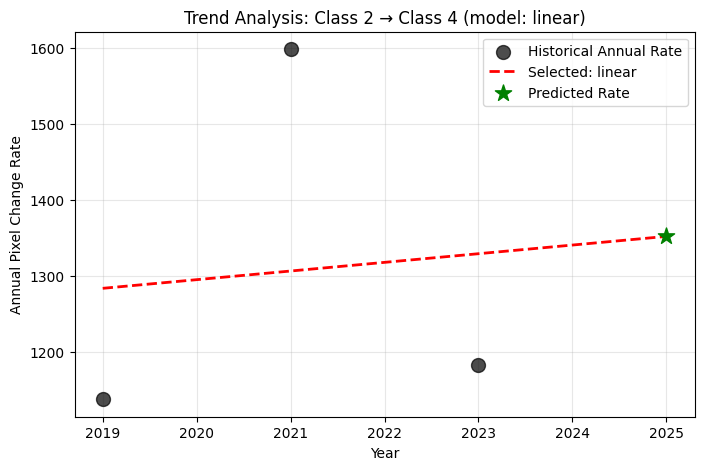

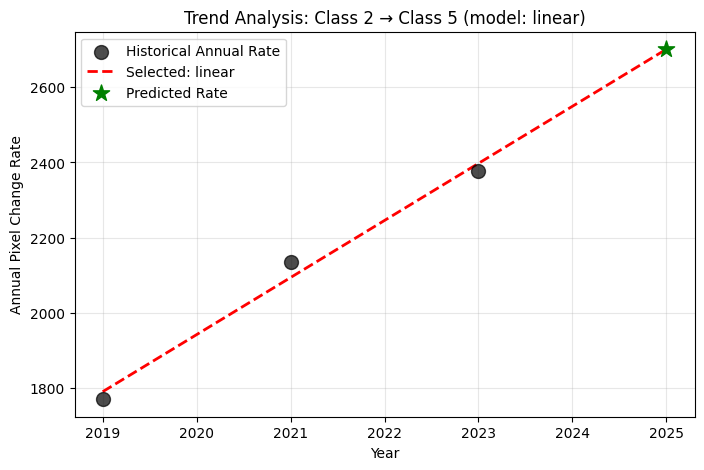

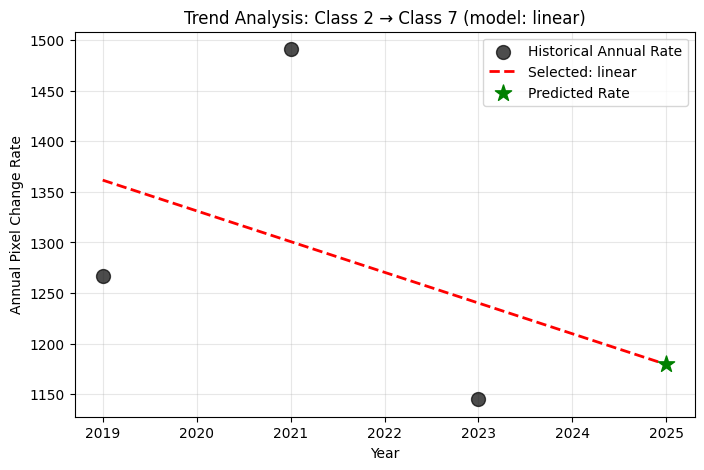

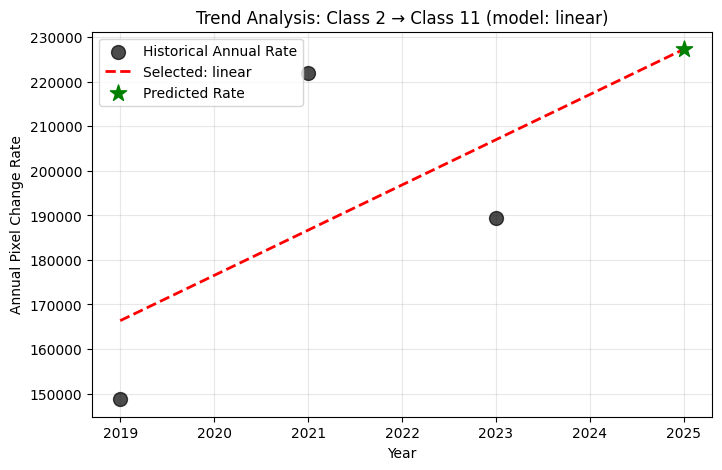

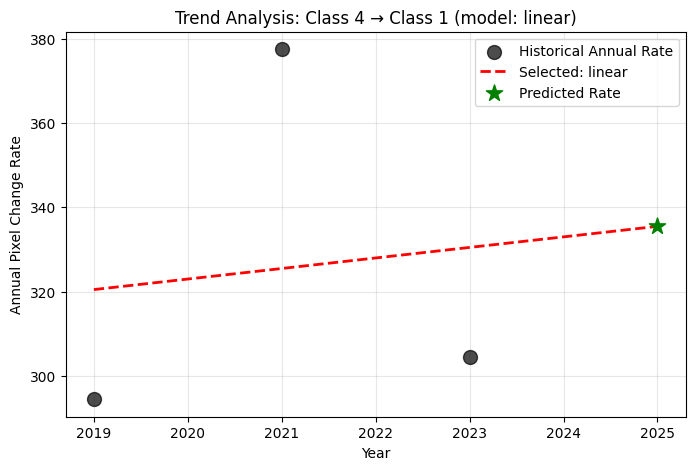

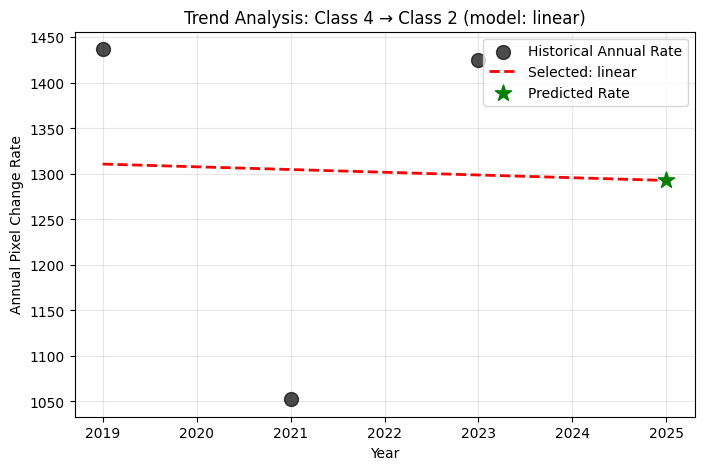

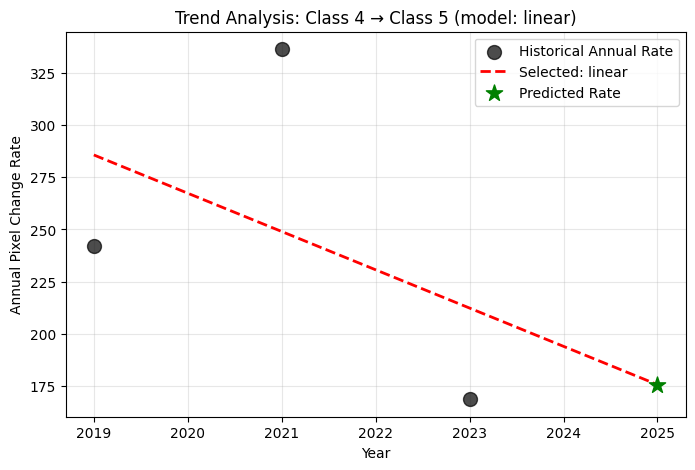

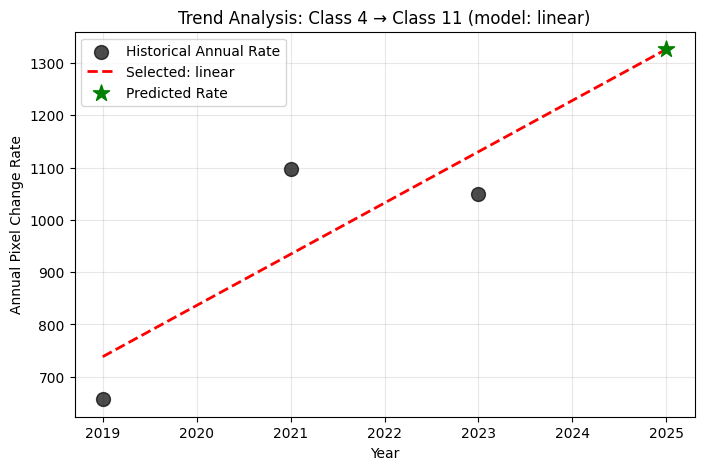

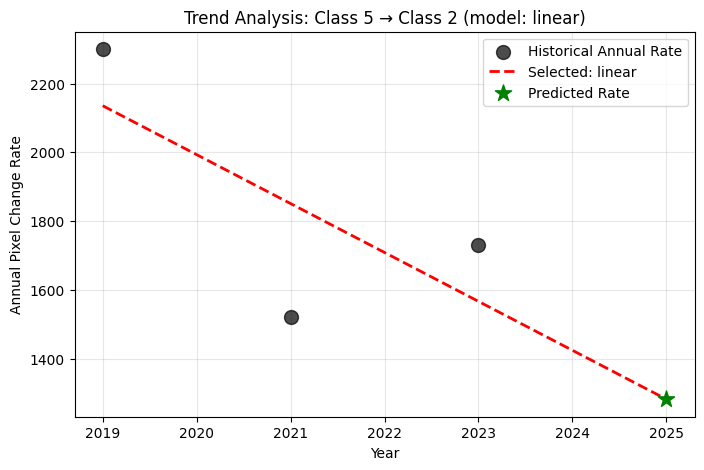

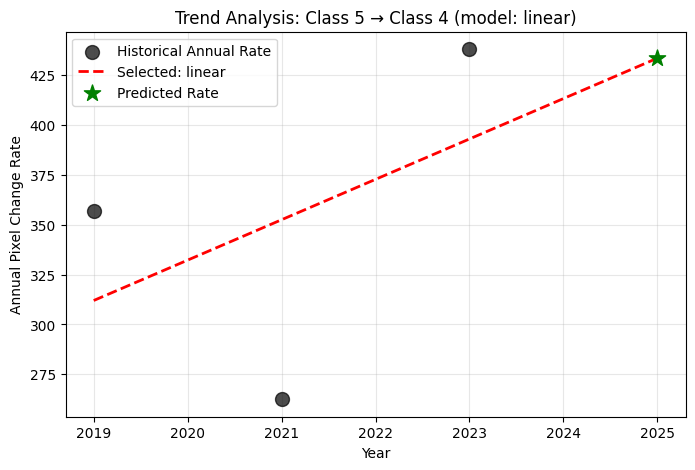

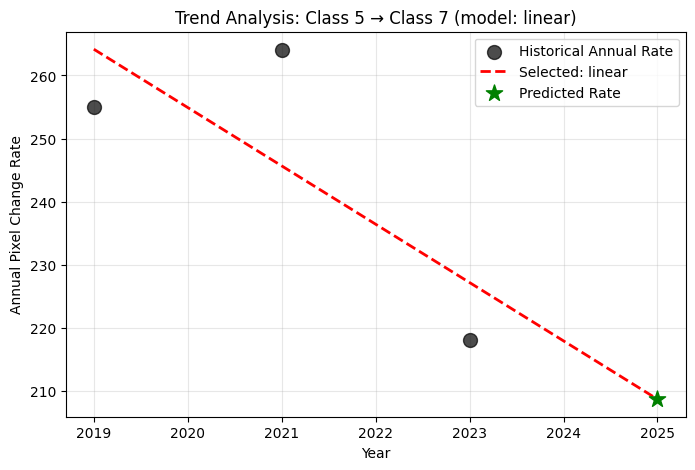

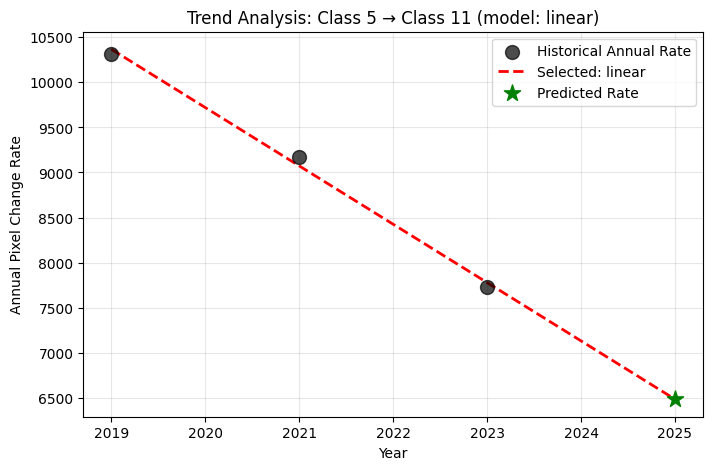

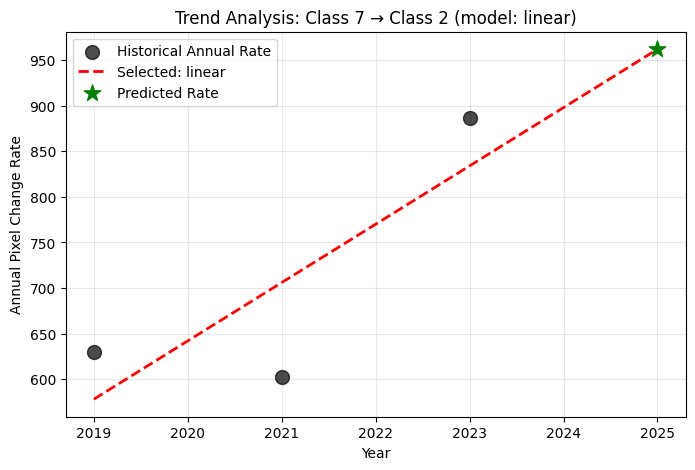

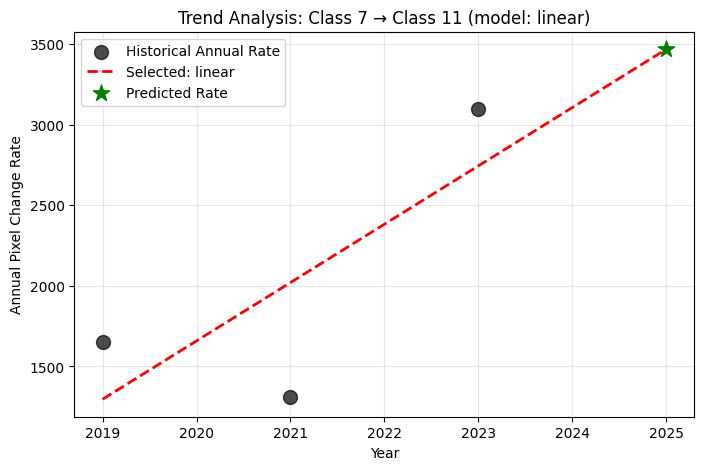

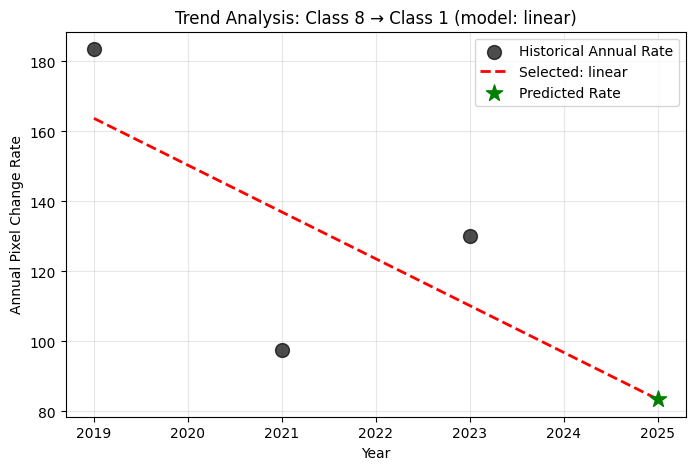

In [ ]:
counts, matrix_mode = None, None
if not DEMO_MODE:
    matrix, counts, _plots, analysis_mode = change_analysis.run_change_analysis(target_files)  # 4-tuple, not 3
    matrix_mode = analysis_mode
    print("Trend-fitting mode used:", matrix_mode, "(expect 'Non-Linear Trend' with 4 epochs)")
else:
    from_codes = list(range(1, 12))
    counts = pd.DataFrame(np.random.default_rng(1).integers(0, 5000, size=(len(from_codes), len(from_codes))),
                          index=from_codes, columns=from_codes)
    matrix_mode = "Non-Linear Trend (demo)"

MIN_PIXELS = dcfg.DEFOR_PARAMS["min_pixels_transition"]  # 200, documented rationale in config
significant_transitions = [(int(i), int(j)) for i in counts.index for j in counts.columns
                           if int(i) != int(j) and float(counts.loc[i, j]) >= MIN_PIXELS]
print(f"{len(significant_transitions)} significant transitions (>= {MIN_PIXELS} px)")


## 7. Deforestation results (Table 2: forest cover/loss; Table 3: what forest became)

In [ ]:
y0, y1 = min(ANALYSIS_YEARS), max(ANALYSIS_YEARS)
area = ST.pixel_area_ha(REF_PROFILE, shape=tc.shape)  # scalar or per-row array -- both handled by _area_of_mask

print("=== Table 2: forest cover / annual loss (country-clipped) ===")
for yr in sorted(defo["forest_by_year"].keys()):
    forest_ha = ST._area_of_mask(defo["forest_by_year"][yr], area)
    loss_ha = ST._area_of_mask(defo["loss_by_year"][yr], area) if yr in defo.get("loss_by_year", {}) else None
    print(f"  {yr}: forest {forest_ha:>12,.0f} ha" + (f" | loss: {loss_ha:>10,.0f} ha" if loss_ha else ""))

print("\n=== Table 3: what Hansen-detected deforested pixels became (exact, not estimated) ===")
CLASS_NAMES = {1: "Water", 2: "Trees", 4: "Flooded Vegetation", 5: "Crops",
               7: "Built Area", 8: "Bare Ground", 11: "Rangeland"}
hansen_deforested = defo["loss_window_mask"] & defo["forest_by_year"][y0]
became = lulc_by_year[y1][hansen_deforested]
table3 = pd.Series(became).value_counts().sort_values(ascending=False)
for cls, n in table3.items():
    print(f"  {CLASS_NAMES.get(int(cls), f'Class {int(cls)}'):<20} {n:>10,} px")


=== Table 2: forest cover / annual loss (country-clipped) ===
  2018: forest    5,464,804 ha | loss:    933,580 ha
  2019: forest    4,944,635 ha | loss:    986,291 ha
  2020: forest    4,445,306 ha | loss:    866,314 ha
  2021: forest    3,975,667 ha | loss:    840,295 ha
  2022: forest    3,604,681 ha | loss:    719,126 ha
  2023: forest    3,172,493 ha | loss:    889,395 ha
  2024: forest    2,723,699 ha | loss:    954,369 ha

=== Table 3: what Hansen-detected deforested pixels became (exact, not estimated) ===
  Trees                   342,848 px
  Rangeland                92,099 px
  Built Area                1,219 px
  Crops                       908 px
  Flooded Vegetation          743 px
  Water                       583 px
  Bare Ground                   1 px


In [ ]:
# --- A1. Is the pixel-area constant right? ----------------------------------
# Everything downstream is in hectares via `area`, so check it against a known
# published figure before trusting any hectare number in the report.

grid_ha = ST._area_of_mask(boundary_mask, area)
print(f"Grid area inside Guinea's polygon : {grid_ha:>14,.0f} ha")
print(f"Guinea land area (published)      : {24_585_700:>14,.0f} ha  (245,857 km^2)")
print(f"Ratio                             : {grid_ha / 24_585_700:>14.3f}")
print()
print("Expect ~1.00. If this is materially off, every hectare figure in the")
print("report is off by the same factor and this is the first thing to fix.")

In [ ]:
# --- A2. Where does the loss/extent discrepancy come from? ------------------
import numpy as np, pandas as pd

yrs = sorted(defo["forest_by_year"].keys())
rows = []
for i, yr in enumerate(yrs):
    if i == 0:
        continue
    prev  = yrs[i - 1]
    f_prev = defo["forest_by_year"][prev]
    f_now  = defo["forest_by_year"][yr]

    extent_decline = (ST._area_of_mask(f_prev, area)
                      - ST._area_of_mask(f_now, area))

    lm = defo.get("loss_by_year", {}).get(yr)
    if lm is None:
        print(f"  {yr}: no loss_by_year entry -- skipped")
        continue

    loss_reported = ST._area_of_mask(lm, area)            # what Table 5 prints now
    loss_in_forest = ST._area_of_mask(lm & f_prev, area)  # GFW convention
    loss_outside   = ST._area_of_mask(lm & ~f_prev, area) # the suspect residual

    rows.append(dict(
        year=yr,
        extent_decline_ha=extent_decline,
        loss_reported_ha=loss_reported,
        loss_in_forest_ha=loss_in_forest,
        loss_outside_forest_ha=loss_outside,
        ratio=loss_reported / extent_decline if extent_decline else np.nan,
    ))

recon = pd.DataFrame(rows)
with pd.option_context("display.float_format", lambda v: f"{v:,.0f}"):
    print(recon.to_string(index=False))

print()
print(f"TOTAL reported loss      : {recon.loss_reported_ha.sum():>14,.0f} ha")
print(f"TOTAL loss inside forest : {recon.loss_in_forest_ha.sum():>14,.0f} ha")
print(f"TOTAL extent decline     : {recon.extent_decline_ha.sum():>14,.0f} ha")
print()
print("HOW TO READ THIS")
print(" (a) loss_in_forest ~= extent_decline, and loss_reported >> both:")
print("     the extent calculation is correct and the annual-loss column is")
print("     counting Hansen loss in pixels below the 30% canopy threshold, i.e.")
print("     pixels that were never 'forest' by this report's own definition.")
print("     FIX: report loss_in_forest_ha. That is also the GFW convention, so")
print("     the numbers become comparable to the published Guinea figures.")
print()
print(" (b) loss_in_forest is STILL >> extent_decline:")
print("     the annual loss masks overlap across years. Check that")
print("     loss_by_year[Y] is (ly == Y-2000) and not a cumulative mask.")

In [ ]:
# --- A3. Section 6.2 says 5.46 Mha forest in 2018 at 30% canopy.
#         Section 6.10 says 9.16 Mha, same threshold, same year.
#         Only one can be right. Recompute both from scratch.

thr_cfg = dcfg.DEFOR_PARAMS["canopy_threshold_pct"]
print(f"Configured canopy threshold: {thr_cfg}%\n")

for thr in [10, 30, 50]:
    seed  = F.forest_mask_from_hansen(tc, canopy_threshold=thr)
    f2018 = F.forest_extent_by_year(seed, ly, [2018])[2018]
    f2024 = F.forest_extent_by_year(seed, ly, [2024])[2024]
    a18 = ST._area_of_mask(f2018, area)
    a24 = ST._area_of_mask(f2024, area)
    print(f"  {thr:>2}% : 2018 {a18:>14,.0f} ha | 2024 {a24:>14,.0f} ha "
          f"| decline {a18-a24:>13,.0f} ha ({100*(a18-a24)/a18:.1f}%)")

print()
print("Reference: Global Forest Watch reports 8.02 Mha tree cover for Guinea in")
print("2010 at 30% canopy (~33% of land area). The 30% row above should be in")
print("that neighbourhood for 2018. Whichever of Section 6.2 / 6.10 this")
print("reproduces is correct; update the other.")

## 8. TRUE temporal hold-outs -- standard step, not optional diagnostics

**8a protocol corrected in this revision.** The earlier version of the
land-cover hold-out silently trained 0 models (misaligned predictor files)
and validated an unchanged persistence map; its printed numbers
(FoM 37.73%/38.58%, OA 90.86%/90.89% \"beating\" the null) are invalid and
must not be cited. The corrected protocol aligns BOTH predictors and the
LC target rasters onto the single reference grid (cell 4b), validates
against the simulation's true starting map, adds a longer-horizon split,
tests standard vs growth-modes+neighborhood-density through one identical
protocol, and RESUMES from on-disk models/suitability maps if a run is
interrupted. 8b (risk model) was always sound and is unchanged.

In [ ]:
# --- 8a. Land-cover hold-out(s) -- CORRECTED protocol, RESUME-AWARE ----------
# Protocol corrections vs the original cell (which silently trained 0 models):
#   (1) predictors AND LC targets both come from the aligned files of cell 4b;
#   (2) hard guards: refuse to continue on 0 trained models / empty atlas;
#   (3) correct validation baseline: ref_t1 = the map the simulation STARTS
#       from (cal end year) -> FoM scores only simulated change, null = TRUE
#       persistence;
#   (4) two configurations through one identical protocol (Section 9 rule):
#       standard (original design) vs growth+nbhd (expander+patcher modes +
#       per-class neighborhood density -- the Land Use module's validated best);
#   (5) a third, longer-horizon split (cal 2018-2020 -> test 2024), demand
#       scaled linearly to the window.
# RESUME: an interrupted run leaves its expensive artifacts on disk -- trained
# models (model_*.joblib + *_features.json) and finished suitability maps
# (suitability_*.tif). This cell detects them per split/config, reuses them,
# and only trains/generates what is missing. Allocation + validation (cheap)
# always re-run. A partially-written suitability file from the moment of
# interruption is detected (unreadable/wrong grid) and regenerated.
import rasterio
from landuse_tool import scenarios

land_cover_holdout_results = {}

lc_splits = [((2018, 2020), 2022),
             ((2020, 2022), 2024),
             ((2018, 2020), 2024)]   # longer-horizon forward test

LC_HOLDOUT_CONFIGS = ["standard", "growth+nbhd"]
NBHD_RADIUS_PX = 5   # 5 px at 250 m = 1.25 km window, matching the Land Use module


def _neighborhood_files(lc_file, out_dir, expected_basenames=None):
    """Per-class density rasters for lc_file (same grid as lc_file). Classes
    present at training but absent in this map get an all-zeros raster; extra
    classes are dropped. Reuses files already on disk from a previous run."""
    os.makedirs(out_dir, exist_ok=True)
    existing = sorted(
        os.path.join(out_dir, f) for f in os.listdir(out_dir) if f.endswith(".tif"))
    paths = existing or scenarios.generate_neighborhood_predictors(
        lc_file, out_dir, radius_pixels=NBHD_RADIUS_PX)
    if expected_basenames is not None:
        have = {os.path.basename(p) for p in paths}
        with rasterio.open(lc_file) as src:
            prof = src.profile.copy()
        prof.update(dtype="float32", count=1)
        for bn in expected_basenames:
            if bn not in have:
                p = os.path.join(out_dir, bn)
                with rasterio.open(p, "w", **prof) as dst:
                    dst.write(np.zeros((prof["height"], prof["width"]),
                                       dtype="float32"), 1)
                paths.append(p)
        paths = [p for p in paths if os.path.basename(p) in set(expected_basenames)]
    return sorted(paths)


def _models_on_disk(models_dir, transitions, growth):
    """Reconstruct the {key: model_path} dict from a previous run's artifacts.
    A model counts only if its _features.json schema file is present too."""
    found = {}
    modes = ("expander", "patcher") if growth else ("standard",)
    for (f, t) in transitions:
        for mode in modes:
            if mode == "standard":
                p = os.path.join(models_dir, f"model_{f}_{t}.joblib")
                key = (f, t)
            else:
                p = os.path.join(models_dir, f"model_{mode}_{f}_{t}.joblib")
                key = (f, t, mode)
            if os.path.exists(p) and os.path.exists(
                    p.replace(".joblib", "_features.json")):
                found[key] = p
    return found


def _suit_path(suit_dir, key):
    if len(key) == 3:
        f, t, mode = key
        return os.path.join(suit_dir, f"suitability_{mode}_{f}_to_{t}.tif")
    f, t = key
    return os.path.join(suit_dir, f"suitability_{f}_to_{t}.tif")


def _usable_raster(path, ref_hw):
    """True if path exists, opens cleanly and is on the reference grid --
    guards against the half-written file from an interrupted run."""
    if not os.path.exists(path):
        return False
    try:
        with rasterio.open(path) as src:
            return src.shape == ref_hw
    except Exception:
        return False


if DEMO_MODE or not predictor_files_aligned:
    print("DEMO_MODE / empty predictor set: skipping land-cover hold-outs cleanly.")
else:
    _ref_hw = (REF_PROFILE["height"], REF_PROFILE["width"])

    for cal_pair, test_year in lc_splits:
        cal_start, cal_end = cal_pair
        t_start = next(t["file"] for t in target_files_aligned if t["year"] == cal_start)
        t_end = next(t["file"] for t in target_files_aligned if t["year"] == cal_end)
        t_test = next(t["file"] for t in target_files_aligned if t["year"] == test_year)

        matrix_cal, counts_cal, _ = change_analysis.calculate_transition_matrix(t_start, t_end)
        sig_cal = [(int(i), int(j)) for i in counts_cal.index for j in counts_cal.columns
                   if int(i) != int(j) and float(counts_cal.loc[i, j]) >= MIN_PIXELS]

        span_ratio = (test_year - cal_end) / (cal_end - cal_start)
        counts_test = counts_cal * span_ratio if span_ratio != 1 else counts_cal

        with rasterio.open(t_end) as s:
            ref_t1 = s.read(1)          # simulation starting map = correct baseline
        with rasterio.open(t_test) as s:
            ref_t2_actual = s.read(1)

        for cfg in LC_HOLDOUT_CONFIGS:
            label = f"{cal_start}-{cal_end} -> {test_year} [{cfg}]"
            run_dir = os.path.join(
                OUT_DIR, f"holdout_{cal_end}_{test_year}_{cfg.replace('+', '_')}")
            models_dir = os.path.join(run_dir, "models")
            suit_dir = os.path.join(run_dir, "suitability")
            pred_dir = os.path.join(run_dir, "prediction")
            for d in (models_dir, suit_dir, pred_dir):
                os.makedirs(d, exist_ok=True)

            growth = cfg != "standard"
            if not growth:
                train_files = list(predictor_files_aligned)
                atlas_files = list(predictor_files_aligned)
            else:
                nb_train = _neighborhood_files(
                    t_start, os.path.join(run_dir, "nbhd_train"))
                expected = [os.path.basename(p) for p in nb_train]
                nb_test = _neighborhood_files(
                    t_end, os.path.join(run_dir, "nbhd_test"),
                    expected_basenames=expected)
                train_files = list(predictor_files_aligned) + nb_train
                atlas_files = list(predictor_files_aligned) + nb_test

            # ---- TRAINING (resume-aware) ------------------------------------
            model_paths_cal = _models_on_disk(models_dir, sig_cal, growth)
            done_transitions = {(k[0], k[1]) for k in model_paths_cal}
            # In growth mode a transition may legitimately have only one mode's
            # model (the other skipped for insufficient samples); transitions
            # with at least one saved model are treated as done.
            todo = [tr for tr in sig_cal if tr not in done_transitions]
            print(f"{label}: reusing {len(model_paths_cal)} model(s) from disk; "
                  f"training {len(todo)}/{len(sig_cal)} transition(s)")
            if todo:
                new_models, _ = training.train_transition_models(
                    todo, [t for t in target_files_aligned if t["year"] in cal_pair],
                    train_files, use_growth_modes=growth, temp_dir=models_dir)
                model_paths_cal.update(new_models)
            if not model_paths_cal:
                raise RuntimeError(
                    f"{label}: 0 transition models trained -- predictor "
                    f"alignment problem; refusing to validate a persistence map.")

            # ---- SUITABILITY ATLAS (resume-aware) ---------------------------
            suit_cal, atlas_todo = {}, {}
            for key, mp in model_paths_cal.items():
                sp = _suit_path(suit_dir, key)
                if _usable_raster(sp, _ref_hw):
                    suit_cal[key] = sp
                else:
                    atlas_todo[key] = mp
            print(f"{label}: reusing {len(suit_cal)} suitability map(s); "
                  f"generating {len(atlas_todo)}")
            if atlas_todo:
                suit_new = prediction.generate_suitability_atlas(
                    atlas_files, t_end, atlas_todo, temp_dir=suit_dir)
                suit_cal.update(suit_new)
            if not suit_cal:
                raise RuntimeError(f"{label}: suitability atlas is empty.")

            # ---- ALLOCATION + VALIDATION (always re-run; cheap) -------------
            pred_test = prediction.run_allocation_simulation(
                t_end, counts_test, suit_cal, temp_dir=pred_dir)

            with rasterio.open(pred_test) as s:
                pred_t2 = s.read(1)
            report = validation.validate_simulation(
                ref_t1, ref_t2_actual, pred_t2, class_names=CLASS_NAMES)
            land_cover_holdout_results[label] = report

            fom = report["figure_of_merit"]
            print(f"{label}: FoM {fom['figure_of_merit_pct']:.2f}% "
                  f"(hits {fom['hits']:,}, misses {fom['misses']:,}, "
                  f"false alarms {fom['false_alarms']:,}, wrong hits {fom['wrong_hits']:,}), "
                  f"OA {report['accuracy']['overall_accuracy']:.4f} "
                  f"vs TRUE persistence null {fom['null_model_accuracy_pct']:.2f}%")

    print()
    print("Read-out guide:")
    print(" - The null baseline is TRUE persistence of the simulation's own")
    print("   starting map, so OA above it is real forward skill.")
    print(" - FoM will read lower than the previous 37-38% figures: those came")
    print("   from a run with 0 trained models and are invalid.")
    print(" - Expect the 4-year split's FoM above the 2-year splits' -- more")
    print("   observed change raises FoM's ceiling; that is by design.")
    print(" - Compare 'standard' vs 'growth+nbhd' per split and adopt whichever")
    print("   wins consistently (Section 9 rule: test before adopting, always).")


INFO landuse_tool.change_analysis: Valid pixels: 3950610 / 8275938
INFO landuse_tool.change_analysis: Found 8 land cover classes: [1, 2, 4, 5, 7, 8, 10, 11]
INFO landuse_tool.change_analysis: Transition matrix:
          1         2         4         5         7         8             10  \
1   0.942724  0.022601  0.011713  0.002219  0.000722  0.008256  0.000000e+00   
2   0.000231  0.907231  0.000602  0.001222  0.000564  0.000000  0.000000e+00   
4   0.006826  0.047296  0.922906  0.006618  0.000970  0.000000  0.000000e+00   
5   0.002455  0.072283  0.006499  0.579612  0.006066  0.000144  0.000000e+00   
7   0.000255  0.020342  0.000433  0.002826  0.913134  0.000178  2.545890e-05   
8   0.137662  0.001299  0.007792  0.038961  0.002597  0.421429  0.000000e+00   
10  0.000000  0.000000  0.000000  0.000000  0.000000  0.000000  0.000000e+00   
11  0.000589  0.169191  0.000819  0.007527  0.002284  0.000007  6.016083e-07   

          11  
1   0.011765  
2   0.090150  
4   0.015384  
5   0.33

2018-2020 -> 2022 [standard]: reusing 23 model(s) from disk; training 0/23 transition(s)


INFO landuse_tool.prediction: Starting allocation simulation (stochastic=False)
INFO landuse_tool.prediction: Growth mode: False
INFO landuse_tool.prediction: Loaded baseline LC: (2442, 3389)
INFO landuse_tool.prediction: Processing 64 transitions in priority order
INFO landuse_tool.prediction: Transition 11→2: demand=281231 pixels
INFO landuse_tool.prediction: Changed 281231 pixels: 11→2


2018-2020 -> 2022 [standard]: reusing 23 suitability map(s); generating 0


INFO landuse_tool.prediction: Transition 2→11: demand=194525 pixels
INFO landuse_tool.prediction: Changed 194525 pixels: 2→11
INFO landuse_tool.prediction: Transition 5→11: demand=13832 pixels
INFO landuse_tool.prediction: Changed 13832 pixels: 5→11
INFO landuse_tool.prediction: Transition 11→5: demand=12511 pixels
INFO landuse_tool.prediction: Changed 12511 pixels: 11→5
INFO landuse_tool.prediction: Transition 11→7: demand=3797 pixels
INFO landuse_tool.prediction: Changed 3797 pixels: 11→7
INFO landuse_tool.prediction: Transition 5→2: demand=3003 pixels
INFO landuse_tool.prediction: Changed 3003 pixels: 5→2
INFO landuse_tool.prediction: Transition 2→5: demand=2637 pixels
INFO landuse_tool.prediction: Changed 2637 pixels: 2→5
INFO landuse_tool.prediction: Transition 7→11: demand=2467 pixels
INFO landuse_tool.prediction: Changed 2467 pixels: 7→11
INFO landuse_tool.prediction: Transition 4→2: demand=1365 pixels
INFO landuse_tool.prediction: Changed 1365 pixels: 4→2
INFO landuse_tool.pred

...

2018-2020 -> 2024 [growth+nbhd]: reusing 0 model(s) from disk; training 23/23 transition(s)


INFO landuse_tool.training: Using 409 samples per class (balanced)
INFO landuse_tool.training: Sampling 818 pixels from 18 predictors
INFO landuse_tool.training: Loading 18 predictors into memory for vectorized extraction...
INFO landuse_tool.training: Skipped 573 samples with missing values
INFO landuse_tool.training: Successfully created dataset: (245, 18)
INFO landuse_tool.training: Training model with 245 samples, 18 predictors
INFO landuse_tool.training: Train set: 150, Test set: 95 (Spatially isolated)
INFO landuse_tool.training: Test accuracy: 0.6947
INFO landuse_tool.training: CV scores: 0.7333 ± 0.0869
INFO landuse_tool.training: ✅ Model saved to c:\Users\ASUS\Guinea_Project\Land Use-Deforestation\analysis_outputs\holdout_2020_2024_growth_nbhd\models\model_expander_1_2.joblib
INFO landuse_tool.training: ✅ Feature schema saved to c:\Users\ASUS\Guinea_Project\Land Use-Deforestation\analysis_outputs\holdout_2020_2024_growth_nbhd\models\model_expander_1_2_features.json
INFO landus

2018-2020 -> 2024 [growth+nbhd]: reusing 0 suitability map(s); generating 44


INFO landuse_tool.prediction: Suitability map complete: 20269 pixels evaluated
INFO landuse_tool.prediction: ✅ Saved suitability map: c:\Users\ASUS\Guinea_Project\Land Use-Deforestation\analysis_outputs\holdout_2020_2024_growth_nbhd\suitability\suitability_expander_1_to_2.tif
INFO landuse_tool.prediction: Feature schema: ['ASPECT.tif', 'DEM_GEE.tif.tif', 'POI_heatmap.tif', 'POPULATION_DENSITY_2020.tif.tif', 'PRECIPITATION_2024.tif.tif', 'RAILWAYS_distance.tif', 'ROADS_distance.tif', 'SLOPE.tif', 'SOIL_MOISTURE_2024.tif.tif', 'TEMPERATURE_2024.tif.tif', 'WATERWAYS_distance.tif', 'neighborhood_class_1.tif', 'neighborhood_class_11.tif', 'neighborhood_class_2.tif', 'neighborhood_class_4.tif', 'neighborhood_class_5.tif', 'neighborhood_class_7.tif', 'neighborhood_class_8.tif']
INFO landuse_tool.prediction: Generating patcher suitability map 2/44: 1→2
INFO landuse_tool.prediction: Generating suitability map: patcher (model: model_patcher_1_2.joblib)
INFO landuse_tool.prediction: ✅ Loaded mode

2018-2020 -> 2024 [growth+nbhd]: FoM 19.70% (hits 274,500, misses 346,387, false alarms 753,337, wrong hits 18,893), OA 0.8648 vs TRUE persistence null 92.27%

Read-out guide:
 - The null baseline is TRUE persistence of the simulation's own
   starting map, so OA above it is real forward skill.
 - FoM will read lower than the previous 37-38% figures: those came
   from a run with 0 trained models and are invalid.
 - Expect the 4-year split's FoM above the 2-year splits' -- more
   observed change raises FoM's ceiling; that is by design.
 - Compare 'standard' vs 'growth+nbhd' per split and adopt whichever
   wins consistently (Section 9 rule: test before adopting, always).


In [ ]:
# --- 8b. Deforestation risk-model hold-out, rolling-origin (3 historical splits) ---
# Uses the ADOPTED default config directly (no manual filtering -- confirmed the correct
# default via true hold-out; see Methodology Section 9.1).
risk_holdout_results = {}
splits = [([2015, 2016, 2017, 2018], 2018, 2022),
          ([2013, 2014, 2015, 2016], 2016, 2020),
          ([2010, 2011, 2012, 2013], 2013, 2017)]

for cal_years, test_start, test_end in splits:
    forest_seed = F.forest_mask_from_hansen(tc)
    forest_test_start = F.forest_extent_by_year(forest_seed, ly, [test_start])[test_start]

    prior_loss_cal = D.cumulative_loss(ly, up_to_year=min(cal_years))
    loss_window_cal = D.cumulative_loss(ly, up_to_year=max(cal_years)) & ~prior_loss_cal
    forest_cal_end = F.forest_extent_by_year(forest_seed, ly, [max(cal_years)])[max(cal_years)]
    stable_forest_cal = forest_cal_end & ~loss_window_cal

    driver_stack_cal = DR.build_driver_stack(shared_predictors, forest_cal_end, prior_loss_cal, profile=REF_PROFILE)
    X, y, names = DR.sample_training(loss_window_cal, stable_forest_cal, driver_stack_cal,
                                     samples_per_class=dcfg.DEFOR_PARAMS["samples_per_class"])
    model, cv_metrics = DR.fit_risk_model(X, y, model_type=dcfg.DEFOR_PARAMS["driver_model"])

    prior_loss_test = D.cumulative_loss(ly, up_to_year=test_start)
    driver_stack_test = DR.build_driver_stack(shared_predictors, forest_test_start, prior_loss_test, profile=REF_PROFILE)
    risk_test = DR.predict_risk_map(model, driver_stack_test, names, forest_test_start)
    observed_loss_test = D.cumulative_loss(ly, up_to_year=test_end) & ~prior_loss_test

    auc = validation.risk_map_auc(risk_test, observed_loss_test, forest_test_start)
    label = f"{min(cal_years)}-{max(cal_years)}"
    risk_holdout_results[label] = {"cv": cv_metrics, "auc": auc,
                                    "driver_stack_cal": driver_stack_cal, "driver_stack_test": driver_stack_test,
                                    "loss_window_cal": loss_window_cal, "stable_forest_cal": stable_forest_cal,
                                    "forest_test_start": forest_test_start, "observed_loss_test": observed_loss_test}
    print(f"{label} -> {test_start}-{test_end}: cal CV {cv_metrics['cv_accuracy_mean']:.4f}, "
          f"hold-out AUC {auc['auc']:.4f}")

print("\nExpect AUC around 0.69 for the most recent split (2015-2018), stable/improving for older",
      "splits too (this is the confirmed, adopted default -- Section 9.1). If the most recent split",
      "comes back near chance again, something regressed -- check dist_forest_edge truly defaults off.")


KeyboardInterrupt: 

In [ ]:
# pip install forestatrisk

     ---------------------------------------- 0.0/940.6 kB ? eta -:--:--
     ----------- ---------------------------- 262.1/940.6 kB ? eta -:--:--
     ---------------------------------------- 940.6/940.6 kB 7.3 MB/s  0:00:00
  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Getting requirements to build wheel: started
  Getting requirements to build wheel: finished with status 'done'
  Preparing metadata (pyproject.toml): started
  Preparing metadata (pyproject.toml): finished with status 'done'
   ---------------------------------------- 0.0/1.3 MB ? eta -:--:--
   ---------------------------------------- 1.3/1.3 MB 13.5 MB/s  0:00:00
   ---------------------------------------- 0.0/1.5 MB ? eta -:--:--
   ----------------------------------- ---- 1.3/1.5 MB 22.3 MB/s eta 0:00:01
   ----------------------------------- ---- 1.3/1.5 MB 22.3 MB/s eta 0:00:01
   ----------------------------------- ---- 1.3/1.5 MB 22.3 MB/s eta 0:00:01


  error: subprocess-exited-with-error
  
  × Building wheel for gdal (pyproject.toml) did not run successfully.
  │ exit code: 1
  ╰─> [126 lines of output]
      Using numpy 2.2.6
      C:\Users\ASUS\AppData\Local\Temp\pip-build-env-utczxaeu\overlay\Lib\site-packages\setuptools\config\_apply_pyprojecttoml.py:82: SetuptoolsWarning: `license` overwritten by `pyproject.toml`
        corresp(dist, value, root_dir)
      C:\Users\ASUS\AppData\Local\Temp\pip-build-env-utczxaeu\overlay\Lib\site-packages\setuptools\config\_apply_pyprojecttoml.py:82: SetuptoolsWarning: `extras_require` overwritten in `pyproject.toml` (optional-dependencies)
        corresp(dist, value, root_dir)
      running bdist_wheel
      running build
      running build_py
      creating build\lib.win-amd64-cpython-310\osgeo
      copying osgeo\gdal.py -> build\lib.win-amd64-cpython-310\osgeo
      copying osgeo\gdalconst.py -> build\lib.win-amd64-cpython-310\osgeo
      copying osgeo\gdalnumeric.py -> build\lib.win-amd

In [ ]:
# # --- B1. forestatrisk cross-check: setup -----------------------------------
# # One-time:  pip install forestatrisk
# #
# # NOTE ON CONVENTIONS (verified against forestatrisk 1.3.2 source):
# #   - far.computeAUC(pos_scores, neg_scores) expects pos_scores to be the
# #     predicted probabilities for the DEFORESTED observations.
# #   - forestatrisk's own `fcc23` column codes 0 = deforested, 1 = forest, which
# #     is inverted relative to normal practice. We do NOT use that column name
# #     here; we encode 1 = deforested throughout and call computeAUC explicitly.
# #     Getting this backwards silently inverts the AUC (0.69 becomes 0.31), so
# #     sanity-check that the numbers below are above 0.5.

# import numpy as np, pandas as pd
# import forestatrisk as far
# from sklearn.linear_model import LogisticRegression

# SPLIT = "2015-2018"           # most recent / most policy-relevant split
# b = risk_holdout_results[SPLIT]

# stack_cal   = b["driver_stack_cal"]
# stack_test  = b["driver_stack_test"]
# loss_cal    = b["loss_window_cal"]
# stable_cal  = b["stable_forest_cal"]
# forest_test = b["forest_test_start"]
# loss_test   = b["observed_loss_test"]
# our_auc     = b["auc"]["auc"]

# print(f"Split {SPLIT}: our own hold-out AUC = {our_auc:.4f}")
# print(f"forestatrisk version: {far.__version__ if hasattr(far,'__version__') else 'see pip show'}")

In [ ]:
# # --- B2. Same sample, same predictors, different modelling code -------------
# # Use OUR balanced calibration sample so the only thing that differs between
# # the two results is the model implementation.

# X_cal, y_cal, names = DR.sample_training(
#     loss_cal, stable_cal, stack_cal,
#     samples_per_class=dcfg.DEFOR_PARAMS["samples_per_class"])

# # patsy needs syntactically valid identifiers
# safe = [n.replace("-", "_").replace(" ", "_").replace(".", "_") for n in names]

# df_cal = pd.DataFrame(np.asarray(X_cal, dtype="float64"), columns=safe)
# df_cal["defor"] = np.asarray(y_cal).astype(int)          # 1 = deforested
# df_cal = df_cal.replace([np.inf, -np.inf], np.nan).dropna()

# # Test set: every standing-forest pixel at test_start, matching how
# # validation.risk_map_auc scores our own model.
# ti = np.where(forest_test)
# df_test = pd.DataFrame(
#     {s: np.asarray(stack_test[n][ti], dtype="float64") for n, s in zip(names, safe)})
# df_test["defor"] = np.asarray(loss_test[ti]).astype(int)
# df_test = df_test.replace([np.inf, -np.inf], np.nan).dropna()

# formula = "defor ~ " + " + ".join(safe)
# print("Formula      :", formula)
# print("Calibration  :", df_cal.shape, "| positives:", int(df_cal.defor.sum()))
# print("Test         :", df_test.shape, "| positives:", int(df_test.defor.sum()))

In [ ]:
# # --- B3. forestatrisk glm and rf, scored on the same temporal hold-out ------
# from patsy import dmatrices, build_design_matrices

# results = {}

# # Design matrices (patsy, as forestatrisk does internally)
# y_d, x_d = dmatrices(formula, data=df_cal, NA_action="drop")
# X_train, Y_train = np.asarray(x_d), np.asarray(y_d)[:, 0]
# (x_te,) = build_design_matrices([x_d.design_info], df_test)
# X_test = np.asarray(x_te)

# # glm (logistic regression) -- forestatrisk's `mod_type="glm"` path
# glm = LogisticRegression(solver="lbfgs", max_iter=1000).fit(X_train, Y_train)
# theta_glm = glm.predict_proba(X_test)[:, 1]
# results["forestatrisk glm"] = far.computeAUC(
#     pos_scores=theta_glm[df_test.defor.values == 1],
#     neg_scores=theta_glm[df_test.defor.values == 0])

# # rf -- forestatrisk's model_random_forest wrapper
# mod_rf = far.model_random_forest(
#     formula=formula, data=df_cal, n_estimators=100, n_jobs=-1)
# theta_rf = mod_rf.predict(new_data=df_test)
# results["forestatrisk rf"] = far.computeAUC(
#     pos_scores=theta_rf[df_test.defor.values == 1],
#     neg_scores=theta_rf[df_test.defor.values == 0])

# print(f"{'model':<24} {'hold-out AUC':>12}")
# print(f"{'-'*24} {'-'*12}")
# print(f"{'this study (RF)':<24} {our_auc:>12.4f}")
# for k, v in results.items():
#     print(f"{k:<24} {v:>12.4f}")
# print()
# print("If these land within roughly +/-0.05 of each other, that is implementation")
# print("corroboration and is what goes in the report. A large gap means something")
# print("differs in the data handling and needs tracing before anything is written.")

In [ ]:
# # --- B4. forestatrisk iCAR: spatially autocorrelated random effects ---------
# # This is the methodologically DIFFERENT model, and therefore the informative
# # comparison. Slower (MCMC) but tractable at 10 km cells for Guinea (~2,500 cells).

# import rasterio
# from rasterio.transform import rowcol, xy

# CSIZE_KM = 10
# tr = REF_PROFILE["transform"]
# H, W = REF_PROFILE["height"], REF_PROFILE["width"]

# # Region extent in the raster CRS
# xmin, ymax = tr * (0, 0)
# xmax, ymin = tr * (W, H)

# nneigh, adj = far.cellneigh(region=(xmin, xmax, ymin, ymax),
#                             csize=CSIZE_KM, rank=1)
# ncell_x = int(np.ceil((xmax - xmin) / (CSIZE_KM / 111.32)))   # degrees, EPSG:4326
# print(f"Spatial cells: {len(nneigh)} at {CSIZE_KM} km")

# def cell_index(rows, cols):
#     """Map raster row/col to forestatrisk cell id."""
#     xs, ys = xy(tr, rows, cols)
#     cx = np.floor((np.asarray(xs) - xmin) / (CSIZE_KM / 111.32)).astype(int)
#     cy = np.floor((ymax - np.asarray(ys)) / (CSIZE_KM / 111.32)).astype(int)
#     return np.clip(cy * ncell_x + cx, 0, len(nneigh) - 1)

# # Cell ids for calibration sample and test set.
# # NOTE: DR.sample_training does not return pixel coordinates. If it can be made
# # to (return the flat indices it sampled), use them here. Otherwise re-draw the
# # calibration sample with coordinates using the block below.
# cal_pos = np.where(loss_cal)
# cal_neg = np.where(stable_cal)
# n_per = dcfg.DEFOR_PARAMS["samples_per_class"]
# rng = np.random.default_rng(42)
# sel_p = rng.choice(len(cal_pos[0]), size=min(n_per, len(cal_pos[0])), replace=False)
# sel_n = rng.choice(len(cal_neg[0]), size=min(n_per, len(cal_neg[0])), replace=False)

# rr = np.concatenate([cal_pos[0][sel_p], cal_neg[0][sel_n]])
# cc = np.concatenate([cal_pos[1][sel_p], cal_neg[1][sel_n]])
# yy = np.concatenate([np.ones(len(sel_p), int), np.zeros(len(sel_n), int)])

# df_cal_icar = pd.DataFrame({s: stack_cal[n][rr, cc].astype("float64")
#                             for n, s in zip(names, safe)})
# df_cal_icar["defor"] = yy
# df_cal_icar["cell"]  = cell_index(rr, cc)
# df_cal_icar = df_cal_icar.replace([np.inf, -np.inf], np.nan).dropna()

# df_test_icar = df_test.copy()
# df_test_icar["cell"] = cell_index(ti[0], ti[1])[df_test.index.values]

# formula_icar = "defor ~ " + " + ".join(safe) + " + cell"

# mod_icar = far.model_binomial_iCAR(
#     suitability_formula=formula_icar,
#     data=df_cal_icar,
#     n_neighbors=nneigh, neighbors=adj,
#     burnin=1000, mcmc=1000, thin=1, beta_start=-99)

# theta_icar = mod_icar.predict(new_data=df_test_icar)
# auc_icar = far.computeAUC(
#     pos_scores=theta_icar[df_test_icar.defor.values == 1],
#     neg_scores=theta_icar[df_test_icar.defor.values == 0])

# print(f"\nforestatrisk iCAR hold-out AUC: {auc_icar:.4f}  (this study: {our_auc:.4f})")
# print("\nDeviance explained is reported by mod_icar; forestatrisk's own docs note")
# print("RF explains far more deviance than iCAR while validating worse, which is")
# print("the overfitting result cited in Section 2.3 of the report.")

## 9. Candidate predictors: test before adopting, always

Same protocol that found the dist_forest_edge fix and correctly rejected NDVI/burned area
(both failed it: near-perfect same-window fit, below-chance hold-out -- see Methodology
Section 6.9). Nighttime lights and WFP prices are NEW candidates, tested here for the first
time. Neither should be treated as adopted regardless of how this comes out, until it clears
this bar on the most recent (most policy-relevant) split.

In [ ]:
# Reuse the most recent split's already-computed calibration/test objects (Section 8b, 2015-2018 -> 2019-2022)
baseline = risk_holdout_results["2015-2018"]
driver_stack_cal = baseline["driver_stack_cal"]
driver_stack_test = baseline["driver_stack_test"]
loss_window_cal = baseline["loss_window_cal"]
stable_forest_cal = baseline["stable_forest_cal"]
forest_test_start = baseline["forest_test_start"]
observed_loss_test = baseline["observed_loss_test"]
baseline_auc = baseline["auc"]["auc"]
print(f"Baseline (adopted, no candidate added) hold-out AUC: {baseline_auc:.4f}")


Baseline (adopted, no candidate added) hold-out AUC: 0.6891


In [ ]:
# --- 9a. Nighttime lights (VIIRS) -- economic-activity proxy ---------------
if not DEMO_MODE and nightlights_paths:
    nl_baseline_year = min(nightlights_paths.keys())
    nl_array = data_loader.load_and_align_raster(nightlights_paths[nl_baseline_year], REF_PROFILE)
    nl_array = np.where(np.isfinite(nl_array), nl_array, np.nanmedian(nl_array)).astype("float32")

    stack_cal_nl = dict(driver_stack_cal); stack_cal_nl["nightlights"] = nl_array
    stack_test_nl = dict(driver_stack_test); stack_test_nl["nightlights"] = nl_array

    X, y, names = DR.sample_training(loss_window_cal, stable_forest_cal, stack_cal_nl,
                                     samples_per_class=dcfg.DEFOR_PARAMS["samples_per_class"])
    model_nl, cv_nl = DR.fit_risk_model(X, y, model_type=dcfg.DEFOR_PARAMS["driver_model"])
    risk_nl = DR.predict_risk_map(model_nl, stack_test_nl, names, forest_test_start)
    auc_nl = validation.risk_map_auc(risk_nl, observed_loss_test, forest_test_start)

    print(f"+ nighttime lights: calibration CV {cv_nl['cv_accuracy_mean']:.4f}, "
          f"hold-out AUC {auc_nl['auc']:.4f} (baseline {baseline_auc:.4f})")
    print("ACCEPT only if this improves on the baseline -- reject and move on otherwise, per Section 9.1/6.9.")


+ nighttime lights: calibration CV 0.6945, hold-out AUC 0.6908 (baseline 0.6891)
ACCEPT only if this improves on the baseline -- reject and move on otherwise, per Section 9.1/6.9.


In [ ]:
# --- 9b. WFP commodity prices -- economic-driver proxy ---------------------
# enabled=False in config by default (Section 8, WFP_PRICES_SOURCE) -- flip locally here to test.
if not DEMO_MODE:
    wfp_csv = api_connector.fetch_wfp_prices(output_filename="wfp_guinea_prices.csv")
    if wfp_csv is None:
        print("WFP price fetch failed -- check network access to data.humdata.org from this environment; "
              "the CKAN Action API endpoint used should not require authentication for this public resource.")
    else:
        # Pick a commodity plausibly linked to agricultural-expansion-driven clearing in Guinea.
        # Check available commodities first rather than assuming "Cocoa" exists in this file:
        df_check = pd.read_csv(wfp_csv, low_memory=False)
        available_commodities = sorted(df_check['commodity'].dropna().unique())
        print(f"Available commodities ({len(available_commodities)} total):", available_commodities)

        # Switched from Rice to Oil (palm): confirmed present in this data (Rice's absence
        # from a truncated, alphabetically-sorted print was misleading -- "Rice" sorts after
        # "Potatoes" and simply wasn't in the first 20 shown; now printing the full list so
        # this can't recur silently). Oil (palm) is also a better-justified choice regardless:
        # palm oil expansion is one of the most literature-documented direct drivers of
        # tropical deforestation, more directly relevant here than a staple-food rationale.
        COMMODITY = "Oil (palm)"
        price_surface = data_loader.rasterize_market_points(
            wfp_csv, COMMODITY, target_year=2018, ref_profile=REF_PROFILE)

        if price_surface is not None:
            stack_cal_wfp = dict(driver_stack_cal); stack_cal_wfp["commodity_price"] = price_surface
            stack_test_wfp = dict(driver_stack_test); stack_test_wfp["commodity_price"] = price_surface

            X, y, names = DR.sample_training(loss_window_cal, stable_forest_cal, stack_cal_wfp,
                                             samples_per_class=dcfg.DEFOR_PARAMS["samples_per_class"])
            model_wfp, cv_wfp = DR.fit_risk_model(X, y, model_type=dcfg.DEFOR_PARAMS["driver_model"])
            risk_wfp = DR.predict_risk_map(model_wfp, stack_test_wfp, names, forest_test_start)
            auc_wfp = validation.risk_map_auc(risk_wfp, observed_loss_test, forest_test_start)

            print(f"+ {COMMODITY} price: calibration CV {cv_wfp['cv_accuracy_mean']:.4f}, "
                  f"hold-out AUC {auc_wfp['auc']:.4f} (baseline {baseline_auc:.4f})")
            print("ACCEPT only if this improves on the baseline.")
        else:
            print(f"No {COMMODITY} observations for 2018 -- try a different commodity from the list above.")


Available commodities (26 total): ['Beans (niebe, white)', 'Bread', 'Cassava meal (attieke)', 'Cassava meal (gari)', 'Chili (red, dry raw)', 'Eggplants', 'Fish', 'Fish (dry)', 'Fish (smoked)', 'Fonio', 'Groundnuts (shelled)', 'Maize', 'Maize flour', 'Meat (beef)', 'Oil (palm)', 'Oil (vegetable)', 'Onions', 'Onions (imported)', 'Onions (local)', 'Potatoes', 'Rice (imported)', 'Rice (local)', 'Salt', 'Sugar', 'Tomatoes', 'Tomatoes (paste)']


INFO landuse_tool.data_loader: rasterize_market_points: Oil (palm) 2018 interpolated from 130 market observations.


+ Oil (palm) price: calibration CV 0.6985, hold-out AUC 0.6986 (baseline 0.6891)
ACCEPT only if this improves on the baseline.


## 10. Hansen vs. ESRI agreement (quantified, country-clipped by construction)

In [ ]:
from sklearn.metrics import cohen_kappa_score

TREES_CODE = 2
hansen_loss = defo["loss_window_mask"]
esri_loss = (lulc_by_year[y0] == TREES_CODE) & (lulc_by_year[y1] != TREES_CODE)
forest_universe = defo["forest_by_year"][y0]

h = hansen_loss[forest_universe].ravel()
e = esri_loss[forest_universe].ravel()
agreement = float((h == e).mean())
kappa = cohen_kappa_score(h, e)
both, only_h, only_e, neither = int((h & e).sum()), int((h & ~e).sum()), int((~h & e).sum()), int((~h & ~e).sum())

print(f"Agreement: {agreement:.4f} | Kappa: {kappa:.4f} "
      "(Landis & Koch 1977 scale: <0.20 slight, 0.20-0.40 fair, 0.40-0.60 moderate, "
      "0.60-0.80 substantial, 0.80-1.00 almost perfect)")
print(f"Both: {both:,} | Only Hansen: {only_h:,} | Only ESRI: {only_e:,} | Neither: {neither:,}")


Agreement: 0.5470 | Kappa: 0.0965 (Landis & Koch 1977 scale: <0.20 slight, 0.20-0.40 fair, 0.40-0.60 moderate, 0.60-0.80 substantial, 0.80-1.00 almost perfect)
Both: 58,362 | Only Hansen: 380,039 | Only ESRI: 15,815 | Neither: 419,679


## 11. Canopy-threshold sensitivity (country-clipped by construction, no separate mask needed)

In [ ]:
thresholds = {"10% (FAO)": 10, "30% (GFW default)": 30, "50% (stricter)": 50}
threshold_results = {}
for label, thr in thresholds.items():
    forest_thr = F.forest_mask_from_hansen(tc, threshold=thr)
    loss_thr = F.forest_extent_by_year(forest_thr, ly, [y0])[y0] & defo["loss_window_mask"]
    forest_ha = ST._area_of_mask(forest_thr, area)
    loss_ha = ST._area_of_mask(loss_thr, area)
    threshold_results[label] = {"forest_ha": forest_ha, "loss_ha": loss_ha,
                                "pct_lost": 100 * loss_ha / forest_ha if forest_ha else None}
    print(f"{label:<20} | forest: {forest_ha:>12,.0f} ha | loss: {loss_ha:>10,.0f} ha | "
          f"{threshold_results[label]['pct_lost']:.1f}% lost")

guinea_total_ha = 24_585_700
for label, v in threshold_results.items():
    assert v["forest_ha"] < guinea_total_ha, f"BROKEN: {label} exceeds Guinea's total land area"
print("\nSanity check passed.")


10% (FAO)            | forest:   23,516,747 ha | loss:  5,222,341 ha | 22.2% lost
30% (GFW default)    | forest:    9,162,088 ha | loss:  2,741,104 ha | 29.9% lost
50% (stricter)       | forest:    1,711,524 ha | loss:    543,069 ha | 31.7% lost

Sanity check passed.


## 12. Administrative-zone breakdown

In [ ]:
if not DEMO_MODE:
    zonal = ST.zonal_deforestation(defo["loss_window_mask"], zones_gdf, REF_PROFILE, name_field="name")
    print(zonal.sort_values("loss_ha", ascending=False).to_string(index=False))
    print(f"\nSum across zones: {zonal['loss_ha'].sum():,.0f} ha "
          f"(sanity-check against Table 2's national total above)")


                     zone   loss_ha
    Préfecture de Faranah 343809.64
     Préfecture de Kankan 333470.39
                    Beyla 313904.49
  Préfecture de Kouroussa 285473.79
       Préfecture de Boké 277648.04
     Préfecture de Gaoual 266262.26
   Préfecture de Télimélé 265990.67
      Préfecture de Mamou 245715.89
Préfecture de Kissidougou 241073.35
     Préfecture de Kindia 229520.44
   Préfecture de Kérouané 213274.92
    Préfecture de Siguiri 194336.27
   Préfecture de Mandiana 182856.20
                  Macenta 182401.72
                Nzérékoré 160946.63
      Préfecture de Boffa 144156.47
       Préfecture de Mali 139559.76
                     Lola 129691.01
               Dinguiraye 126909.61
       Préfecture de Pita 116535.98
     Préfecture de Dabola 105915.29
    Préfecture de Dubréka  97014.38
 Préfecture de Forécariah  94368.70
                Guéckédou  92227.87
                    Yomou  85266.51
    Préfecture de Lelouma  68072.08
     Préfecture de Dalaba  6

## 13. Forward scenarios (adopted config, already correct -- no manual fix-up needed)

`defo['risk_map']` from Section 5 is already the adopted (dist_forest_edge-excluded) forward
configuration, since `pipeline.run_from_arrays` now builds it that way by default.

In [ ]:
if not DEMO_MODE and "risk_map" in defo:
    # Protected-area scenario: was a genuinely missing fetch function, not a
    # blocked-access issue (WDPA is public). Fetches once, cached like everything
    # else in this pipeline. If this fails for any reason, falls back to running
    # without it -- the BAU/accelerated scenarios below don't depend on it.
    protected_mask = None
    wdpa_geojson = api_connector.fetch_gee_feature_collection(
        "WCMC/WDPA/current/polygons", boundary_gdf, "wdpa_protected_areas.geojson")
    if wdpa_geojson:
        import geopandas as gpd
        wdpa_gdf = gpd.read_file(wdpa_geojson)
        protected_mask = data_loader.create_boundary_mask(wdpa_gdf, REF_PROFILE)
        print(f"Protected areas: {protected_mask.sum():,} of {protected_mask.size:,} grid pixels "
              f"({100*protected_mask.sum()/protected_mask.size:.1f}%) fall within a WDPA zone.")
    else:
        print("Protected-area fetch did not return data -- proceeding without the protected-area scenario.")

    forest_now = defo["forest_by_year"][max(ANALYSIS_YEARS)]
    loss_ha_by_year = ST.annual_deforestation_area(defo["loss_by_year"], profile=REF_PROFILE)
    forest_ha_by_year = ST.forest_cover_trajectory(defo["forest_by_year"], profile=REF_PROFILE)

    bau = SC.run_scenario(defo["risk_map"], forest_now, loss_ha_by_year, [2025, 2026, 2027],
                          pixel_area_ha=area, forest_ha_by_year=forest_ha_by_year, profile=REF_PROFILE)
    accel = SC.run_scenario(defo["risk_map"], forest_now, loss_ha_by_year, [2025, 2026, 2027],
                            pixel_area_ha=area, forest_ha_by_year=forest_ha_by_year, profile=REF_PROFILE,
                            rate_factor=1.5)

    print("Business-as-usual projected loss (ha/yr):", bau["projected_loss_ha"])
    print("BAU total demand (ha):", bau["total_demand_ha"])
    print("Accelerated-frontier (1.5x) total demand (ha):", accel["total_demand_ha"])
    if protected_mask is not None:
        protected_scenario = SC.run_scenario(defo["risk_map"], forest_now, loss_ha_by_year, [2025, 2026, 2027],
                                             pixel_area_ha=area, forest_ha_by_year=forest_ha_by_year,
                                             profile=REF_PROFILE, protected_mask=protected_mask)

        # FIX: total_demand_ha is computed from historical rates BEFORE protected_mask is
        # ever applied (see scenario.run_scenario) -- protection only affects WHERE clearing
        # is allocated (apply_policy zeroes risk inside protected_mask, forcing reallocation
        # elsewhere), not the total amount. Comparing total_demand_ha between BAU and the
        # protected scenario is therefore ALWAYS identical by construction -- that is not a
        # bug, it just isn't the right number to look at. The real effect shows up in how much
        # clearing each scenario allocates INSIDE protected zones specifically.
        # FIX: area is a 2D array here (REF_PROFILE is geographic CRS), not a scalar --
        # mask.sum() * area broadcasts incorrectly (same bug class as the original
        # threshold-sensitivity cell much earlier this session). Use the same proven
        # helper (ST._area_of_mask) that correctly handles both scalar and array area,
        # instead of reimplementing the multiplication by hand again.
        bau_cleared_in_protected = ST._area_of_mask(bau["cleared_mask"] & protected_mask, area)
        protected_cleared_in_protected = ST._area_of_mask(protected_scenario["cleared_mask"] & protected_mask, area)

        print(f"\nClearing allocated INSIDE protected zones:")
        print(f"  Business-as-usual:      {bau_cleared_in_protected:,.0f} ha")
        print(f"  Protected-area scenario: {protected_cleared_in_protected:,.0f} ha")
        print(f"  (protected-area scenario should be at or near 0; BAU should be > 0 if its")
        print(f"   risk map doesn't already avoid these zones on its own)")
        print(f"\nTotal demand (both {bau['total_demand_ha']:,.0f} ha, identical by design -- see note above):")
        print(f"  the same total amount is reallocated OUTSIDE protected zones under protection,")
        print(f"  rather than reduced -- this model assumes displacement, not net avoidance,")
        print(f"  which should be stated explicitly if this scenario goes in the report.")
    else:
        print("\nProtected-area scenario skipped (no WDPA data available this run).")


Protected areas: 1,337,890 of 8,275,938 grid pixels (16.2%) fall within a WDPA zone.


INFO landuse_tool.deforestation_tool.scenario: Allocated 375885 cleared pixels (~2348382 ha)
INFO landuse_tool.deforestation_tool.scenario: Allocated 375885 cleared pixels (~2348382 ha)
WARNING landuse_tool.deforestation_tool.scenario: Demand (410029 px) exceeds available non-protected forest (260680 px) -- capping at capacity rather than allocating into protected areas. This means projected demand exceeds what full protection-area enforcement alone can contain; report this explicitly.
INFO landuse_tool.deforestation_tool.scenario: Allocated 260680 cleared pixels (~1628626 ha)


Business-as-usual projected loss (ha/yr): {2025: 853899.8859999999, 2026: 853899.8859999999, 2027: 853899.8859999999}
BAU total demand (ha): 2561699.66
Accelerated-frontier (1.5x) total demand (ha): 3842549.49

Clearing allocated INSIDE protected zones:
  Business-as-usual:      720,398 ha
  Protected-area scenario: 0 ha
  (protected-area scenario should be at or near 0; BAU should be > 0 if its
   risk map doesn't already avoid these zones on its own)

Total demand (both 2,561,700 ha, identical by design -- see note above):
  the same total amount is reallocated OUTSIDE protected zones under protection,
  rather than reduced -- this model assumes displacement, not net avoidance,
  which should be stated explicitly if this scenario goes in the report.


## 13b. Figure 8 regeneration: simulated future land-cover map (2027, business-as-usual)

The current notebook lineage never exported this map -- Figure 8 in the report still
comes from the earliest run. This cell is SELF-CONTAINED and EFFICIENT:
it needs only cells 1-4b to have run (imports, cached fetch, curated predictors,
aligned files); it does NOT need the main pipeline (cell 12) or the hold-outs (8a/8b).
It is resume-aware like 8a: trained models and finished suitability maps are reused
from disk on re-run, so an interruption costs nothing.

Design (consistent with the report text for Section 6.8): calibrate transition models
on the most recent observed interval (2022->2024), generate suitability over the 2024
baseline, extrapolate the observed transition demand linearly to the 2024->2027 horizon
(1.5x the 2-year interval), and allocate demand to the highest-suitability pixels.
Outputs: a GeoTIFF of the simulated 2027 map + report-ready figure8 PNG.

INFO landuse_tool.change_analysis: Valid pixels: 3950610 / 8275938
INFO landuse_tool.change_analysis: Found 7 land cover classes: [1, 2, 4, 5, 7, 8, 11]
INFO landuse_tool.change_analysis: Transition matrix:
          1         2         4         5         7             8         11
1   0.898771  0.019438  0.009145  0.003147  0.000425  1.097359e-02  0.058100
2   0.000227  0.877220  0.000573  0.001537  0.000512  9.395503e-07  0.119931
4   0.008905  0.065255  0.885702  0.004146  0.000748  1.019611e-04  0.035143
5   0.001179  0.059757  0.006632  0.668330  0.005546  1.848642e-04  0.258371
7   0.000242  0.023453  0.000396  0.002995  0.865536  2.202158e-04  0.107157
8   0.161529  0.001233  0.000000  0.011097  0.007398  7.274969e-01  0.091245
11  0.000226  0.121506  0.000618  0.011187  0.001652  1.488536e-05  0.864796
INFO landuse_tool.prediction: Starting allocation simulation (stochastic=False)
INFO landuse_tool.prediction: Growth mode: False
INFO landuse_tool.prediction: Loaded baseline LC

Calibration 2022->2024: 23 significant transitions; demand scaled x1.5 for 2024->2027
Reusing 23 model(s); training 0/23
Reusing 23 suitability map(s); generating 0


INFO landuse_tool.prediction: Transition 11→2: demand=306103 pixels
INFO landuse_tool.prediction: Changed 306103 pixels: 11→2
INFO landuse_tool.prediction: Transition 11→5: demand=28183 pixels
INFO landuse_tool.prediction: Changed 28183 pixels: 11→5
INFO landuse_tool.prediction: Transition 5→11: demand=16771 pixels
INFO landuse_tool.prediction: Changed 16771 pixels: 5→11
INFO landuse_tool.prediction: Transition 7→11: demand=7299 pixels
INFO landuse_tool.prediction: Changed 7299 pixels: 7→11
INFO landuse_tool.prediction: Transition 2→5: demand=4906 pixels
INFO landuse_tool.prediction: Changed 4906 pixels: 2→5
INFO landuse_tool.prediction: Transition 11→7: demand=4162 pixels
INFO landuse_tool.prediction: Changed 4162 pixels: 11→7
INFO landuse_tool.prediction: Transition 5→2: demand=3879 pixels
INFO landuse_tool.prediction: Changed 3879 pixels: 5→2
INFO landuse_tool.prediction: Transition 4→2: demand=2880 pixels
INFO landuse_tool.prediction: Changed 2880 pixels: 4→2
INFO landuse_tool.pred

Simulated map saved: c:\Users\ASUS\Guinea_Project\Land Use-Deforestation\analysis_outputs\forward_2024_2027\simulated_landcover_2027_bau.tif

Class area change 2024 -> simulated 2027 (pixels):
  Water                    22,449 ->     20,693  (-1,756)
  Trees                 2,077,417 ->  2,000,527  (-76,890)
  Flooded Vegetation       28,838 ->     28,153  (-685)
  Crops                    51,323 ->     62,972  (+11,649)
  Built Area               43,446 ->     40,705  (-2,741)
  Bare Ground                 896 ->      1,283  (+387)
  Rangeland             1,726,241 ->  1,796,277  (+70,036)


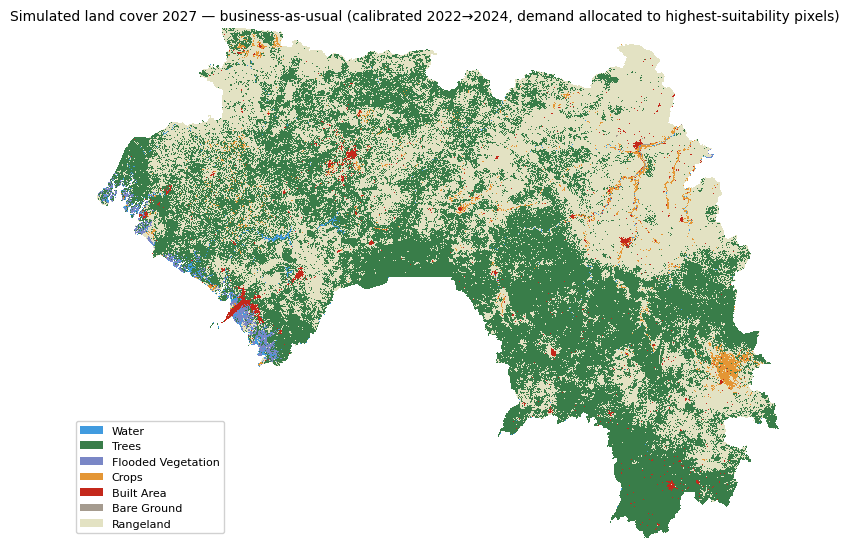

Figure 8 PNG saved: c:\Users\ASUS\Guinea_Project\Land Use-Deforestation\analysis_outputs\figures\figure8_simulated_landcover_2027_bau.png


In [ ]:
# --- 13b. Simulated 2027 land cover (BAU) + Figure 8 export ------------------
import rasterio
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch

FWD_DIR = os.path.join(OUT_DIR, "forward_2024_2027")
for _d in ("models", "suitability", "prediction"):
    os.makedirs(os.path.join(FWD_DIR, _d), exist_ok=True)
FIG_DIR = os.path.join(OUT_DIR, "figures"); os.makedirs(FIG_DIR, exist_ok=True)

_ref_hw = (REF_PROFILE["height"], REF_PROFILE["width"])
CAL_START, CAL_END, TARGET_YEAR = 2022, 2024, 2027

t_start = next(t["file"] for t in target_files_aligned if t["year"] == CAL_START)
t_end   = next(t["file"] for t in target_files_aligned if t["year"] == CAL_END)

# 1. Demand: observed 2022->2024 transitions, scaled linearly to the 3-year horizon.
_, counts_fwd, _ = change_analysis.calculate_transition_matrix(t_start, t_end)
sig_fwd = [(int(i), int(j)) for i in counts_fwd.index for j in counts_fwd.columns
           if int(i) != int(j) and float(counts_fwd.loc[i, j]) >= MIN_PIXELS]
span_ratio = (TARGET_YEAR - CAL_END) / (CAL_END - CAL_START)   # 3 / 2 = 1.5
counts_2027 = counts_fwd * span_ratio
print(f"Calibration {CAL_START}->{CAL_END}: {len(sig_fwd)} significant transitions; "
      f"demand scaled x{span_ratio} for {CAL_END}->{TARGET_YEAR}")

# 2. Training (resume-aware, standard configuration = the adopted one, Section 6.7).
models_dir = os.path.join(FWD_DIR, "models")
model_paths_fwd = {}
for (f, t) in sig_fwd:
    p = os.path.join(models_dir, f"model_{f}_{t}.joblib")
    if os.path.exists(p) and os.path.exists(p.replace(".joblib", "_features.json")):
        model_paths_fwd[(f, t)] = p
todo = [tr for tr in sig_fwd if tr not in model_paths_fwd]
print(f"Reusing {len(model_paths_fwd)} model(s); training {len(todo)}/{len(sig_fwd)}")
if todo:
    new_models, _ = training.train_transition_models(
        todo, [t for t in target_files_aligned if t["year"] in (CAL_START, CAL_END)],
        list(predictor_files_aligned), use_growth_modes=False, temp_dir=models_dir)
    model_paths_fwd.update(new_models)
if not model_paths_fwd:
    raise RuntimeError("0 transition models trained for the forward scenario.")

# 3. Suitability over the 2024 baseline (resume-aware).
suit_dir = os.path.join(FWD_DIR, "suitability")
suit_fwd, atlas_todo = {}, {}
for key, mp in model_paths_fwd.items():
    f, t = key
    sp = os.path.join(suit_dir, f"suitability_{f}_to_{t}.tif")
    ok = False
    if os.path.exists(sp):
        try:
            with rasterio.open(sp) as src:
                ok = src.shape == _ref_hw
        except Exception:
            ok = False
    (suit_fwd if ok else atlas_todo).__setitem__(key, sp if ok else mp)
print(f"Reusing {len(suit_fwd)} suitability map(s); generating {len(atlas_todo)}")
if atlas_todo:
    suit_new = prediction.generate_suitability_atlas(
        list(predictor_files_aligned), t_end, atlas_todo, temp_dir=suit_dir)
    suit_fwd.update(suit_new)
if not suit_fwd:
    raise RuntimeError("Suitability atlas is empty for the forward scenario.")

# 4. Allocation: BAU continuation from the observed 2024 map.
pred_2027_path = prediction.run_allocation_simulation(
    t_end, counts_2027, suit_fwd, temp_dir=os.path.join(FWD_DIR, "prediction"))
with rasterio.open(pred_2027_path) as s:
    pred_2027 = s.read(1)
with rasterio.open(t_end) as s:
    lc_2024 = s.read(1)

# 5. Save the simulated map as a proper GeoTIFF next to the other outputs.
sim_tif = os.path.join(FWD_DIR, f"simulated_landcover_{TARGET_YEAR}_bau.tif")
_prof = dict(REF_PROFILE); _prof.update(driver="GTiff", count=1, dtype="uint8",
                                        nodata=0, tiled=True,
                                        blockxsize=512, blockysize=512)
with rasterio.open(sim_tif, "w", **_prof) as dst:
    dst.write(pred_2027.astype("uint8"), 1)
print("Simulated map saved:", sim_tif)

# 6. Quick sanity read-out: class areas 2024 vs simulated 2027.
print(f"\nClass area change {CAL_END} -> simulated {TARGET_YEAR} (pixels):")
for cls in sorted(CLASS_NAMES):
    a24 = int((lc_2024 == cls).sum()); a27 = int((pred_2027 == cls).sum())
    if a24 or a27:
        print(f"  {CLASS_NAMES[cls]:<20} {a24:>10,} -> {a27:>10,}  ({a27-a24:+,})")

# 7. Figure 8 PNG -- ESRI LULC palette, report-sized (matches the doc's 5.83x3.73 in slot).
ESRI_COLORS = {1: "#419BDF", 2: "#397D49", 4: "#7A87C6", 5: "#E49635",
               7: "#C4281B", 8: "#A59B8F", 10: "#616161", 11: "#E3E2C3"}
present = [c for c in sorted(ESRI_COLORS) if (pred_2027 == c).any()]
cmap = ListedColormap([ESRI_COLORS[c] for c in present])
norm = BoundaryNorm([c - 0.5 for c in present] + [present[-1] + 0.5], cmap.N)
plot_arr = np.ma.masked_where(pred_2027 == 0, pred_2027)   # outside boundary -> blank

fig, ax = plt.subplots(figsize=(8.75, 5.6))                 # 1.5x the doc slot, crisp
ax.imshow(plot_arr, cmap=cmap, norm=norm, interpolation="nearest")
ax.set_title(f"Simulated land cover {TARGET_YEAR} \u2014 business-as-usual "
             f"(calibrated {CAL_START}\u2192{CAL_END}, demand allocated to "
             f"highest-suitability pixels)", fontsize=10)
ax.set_axis_off()
ax.legend(handles=[Patch(facecolor=ESRI_COLORS[c], label=CLASS_NAMES.get(c, str(c)))
                   for c in present],
          loc="lower left", fontsize=8, frameon=True, framealpha=0.9)
plt.tight_layout()
fig8_png = os.path.join(FIG_DIR, f"figure8_simulated_landcover_{TARGET_YEAR}_bau.png")
plt.savefig(fig8_png, dpi=200, bbox_inches="tight")
plt.show()
print("Figure 8 PNG saved:", fig8_png)


## 14. Export everything

In [ ]:
TAB_DIR = os.path.join(OUT_DIR, "tables")
os.makedirs(TAB_DIR, exist_ok=True)

metrics = {
    "mode": "DEMO" if DEMO_MODE else "REAL",
    "lulc_years": LULC_YEARS,
    "trend_fitting_mode": matrix_mode,
    "n_significant_transitions": len(significant_transitions),
    "risk_model_adopted_config": {
        "include_forest_edge": False,
        "cv_accuracy": defo.get("risk_metrics", {}).get("cv_accuracy_mean"),
    },
    "land_cover_holdouts": {
        label: {
            "figure_of_merit_pct": r["figure_of_merit"]["figure_of_merit_pct"],
            "overall_accuracy": r["accuracy"]["overall_accuracy"],
            "null_baseline_pct": r["figure_of_merit"]["null_model_accuracy_pct"],
        } for label, r in land_cover_holdout_results.items()
    },
    "risk_model_holdouts": {
        label: {"cv_accuracy": r["cv"]["cv_accuracy_mean"], "hold_out_auc": r["auc"]["auc"]}
        for label, r in risk_holdout_results.items()
    },
    "hansen_esri_agreement": {"agreement": agreement, "kappa": kappa,
                              "both": both, "only_hansen": only_h, "only_esri": only_e},
    "threshold_sensitivity": {k: {"forest_ha": v["forest_ha"], "loss_ha": v["loss_ha"],
                                  "pct_lost": v["pct_lost"]} for k, v in threshold_results.items()},
}

with open(os.path.join(TAB_DIR, "metrics.json"), "w") as f:
    json.dump(metrics, f, indent=2, default=str)

if not DEMO_MODE and "zonal" in dir():
    zonal.to_csv(os.path.join(TAB_DIR, "table_zonal_breakdown.csv"), index=False)
table3_df = pd.DataFrame({"to_class": [CLASS_NAMES.get(int(c), str(c)) for c in table3.index],
                          "pixels": table3.values})
table3_df.to_csv(os.path.join(TAB_DIR, "table3_forest_conversion.csv"), index=False)

print("Exported to", TAB_DIR)
for f in sorted(os.listdir(TAB_DIR)):
    print("   ", f)

print("\n=== KEY NUMBERS FOR THE REPORT ===")
print("Trend-fitting mode:", matrix_mode)
for label, r in land_cover_holdout_results.items():
    print(f"Land-cover hold-out {label}: FoM {r['figure_of_merit']['figure_of_merit_pct']:.2f}%")
for label, r in risk_holdout_results.items():
    print(f"Risk-model hold-out {label}: AUC {r['auc']['auc']:.4f}")
print(f"Hansen/ESRI agreement: {agreement:.4f}, kappa {kappa:.4f}")


Exported to c:\Users\ASUS\Guinea_Project\Land Use-Deforestation\analysis_outputs\tables
    metrics.json
    table3_forest_conversion.csv
    table_zonal_breakdown.csv

=== KEY NUMBERS FOR THE REPORT ===
Trend-fitting mode: Non-Linear Trend
Land-cover hold-out 2018-2020 -> 2022 [standard]: FoM 15.91%
Land-cover hold-out 2018-2020 -> 2022 [growth+nbhd]: FoM 15.80%
Land-cover hold-out 2020-2022 -> 2024 [standard]: FoM 15.59%
Land-cover hold-out 2020-2022 -> 2024 [growth+nbhd]: FoM 15.69%
Land-cover hold-out 2018-2020 -> 2024 [standard]: FoM 20.80%
Land-cover hold-out 2018-2020 -> 2024 [growth+nbhd]: FoM 19.70%
Risk-model hold-out 2015-2018: AUC 0.6891
Risk-model hold-out 2013-2016: AUC 0.6600
Risk-model hold-out 2010-2013: AUC 0.5642
Hansen/ESRI agreement: 0.5470, kappa 0.0965


## 15. Verify Table 3's Trees-dominance result before it goes in the report

Table 3 (Section 7) showed Trees, not Rangeland, as the dominant fate of Hansen-deforested
pixels -- the opposite of every previously-established result in this project. Hypothesis:
this compares y0=2018 to y1=2024 (6 years), long enough for a shifting-cultivation
clear-farm-fallow-regrow cycle to complete and show as Trees->Trees despite Hansen genuinely
detecting a real disturbance in between. Re-run Table 3 with y1=2022 (matching every earlier
established comparison) using data already in memory -- no re-fetch needed.

In [ ]:
y1_check = 2022  # matches every earlier established Table 3 comparison in this project
hansen_deforested_check = defo["loss_window_mask"] & defo["forest_by_year"][y0] & boundary_mask
became_check = lulc_by_year[y1_check][hansen_deforested_check]
table3_check = pd.Series(became_check).value_counts().sort_values(ascending=False)

print(f"Table 3 recomputed with y1={y1_check} (was y1={y1}):")
for cls, n in table3_check.items():
    print(f"  {CLASS_NAMES.get(int(cls), f'Class {int(cls)}'):<20} {n:>10,} px")

print(f"\nOriginal (y1={y1}) top result: Trees dominant (342,848 px)")
print("If THIS result shows Rangeland dominant instead, the shifting-cultivation/regrowth")
print("hypothesis is confirmed -- both results are real and correct, they just answer")
print("different questions (short-window net conversion vs. long-window including regrowth).")
print("Report the y1=2022 version as the headline (matches prior work, avoids conflating")
print("temporary/cyclical clearing with permanent conversion); the y1=2024 result is a genuinely")
print("interesting secondary finding about regrowth, worth a sentence, not the headline number.")


Table 3 recomputed with y1=2022 (was y1=2024):
  Trees                   348,622 px
  Rangeland                86,149 px
  Built Area                1,213 px
  Crops                       937 px
  Flooded Vegetation          821 px
  Water                       656 px
  Bare Ground                   3 px

Original (y1=2024) top result: Trees dominant (342,848 px)
If THIS result shows Rangeland dominant instead, the shifting-cultivation/regrowth
hypothesis is confirmed -- both results are real and correct, they just answer
different questions (short-window net conversion vs. long-window including regrowth).
Report the y1=2022 version as the headline (matches prior work, avoids conflating
temporary/cyclical clearing with permanent conversion); the y1=2024 result is a genuinely
interesting secondary finding about regrowth, worth a sentence, not the headline number.


## 16. Figures for the report -- missing from this notebook rebuild, added now

These existed in an earlier notebook lineage and were never carried over when this version
was rebuilt from scratch. Genuine gap, not optional polish -- the report needs at least the
forest-trajectory figure and something for the hold-out/agreement results.

INFO matplotlib.category: Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO matplotlib.category: Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


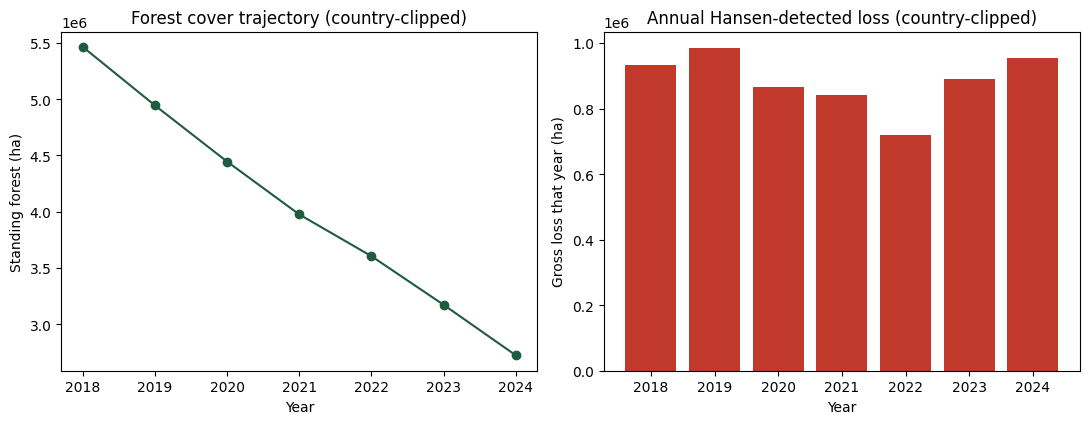

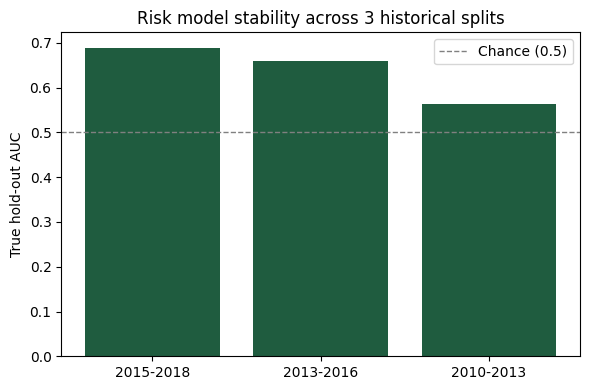

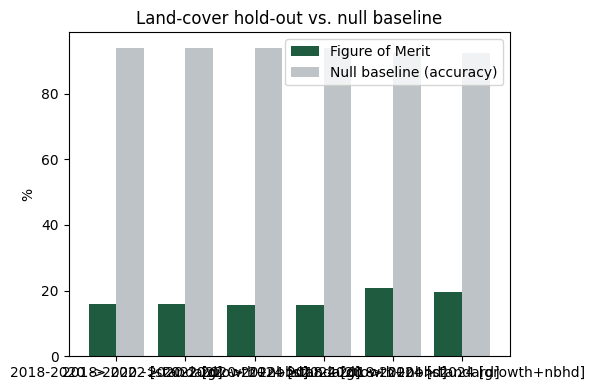

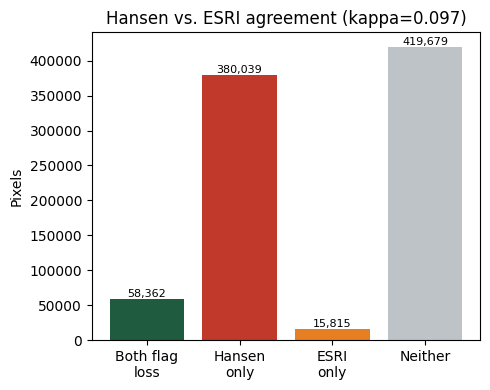

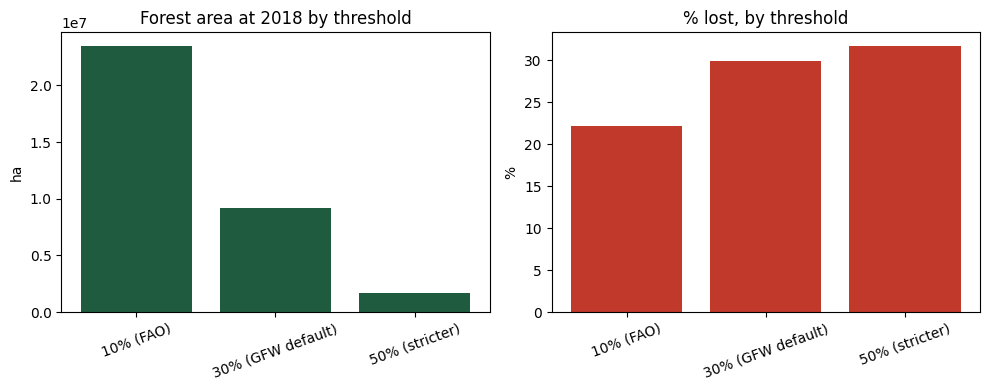

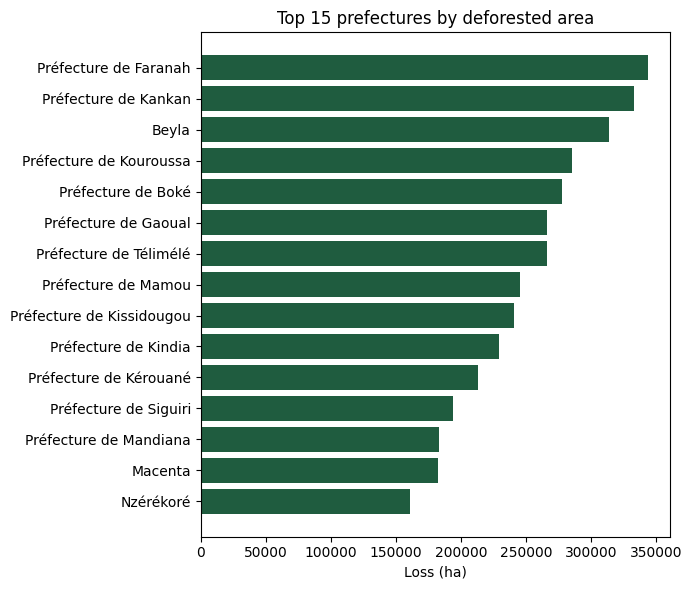

All figures saved to c:\Users\ASUS\Guinea_Project\Land Use-Deforestation\analysis_outputs\figures
    fig_hansen_esri_agreement.png
    fig_landcover_holdout_vs_null.png
    fig_risk_holdout_stability.png
    fig_threshold_sensitivity.png
    fig_zonal_breakdown.png
    figure4_forest_trajectory.png


In [ ]:
import matplotlib.pyplot as plt

FIG_DIR = os.path.join(OUT_DIR, "figures")
os.makedirs(FIG_DIR, exist_ok=True)

# --- Figure 4: forest cover trajectory + annual loss ---
years_sorted = sorted(defo["forest_by_year"].keys())
forest_ha_by_year = {y: ST._area_of_mask(defo["forest_by_year"][y], area) for y in years_sorted}
loss_ha_by_year_fig = {y: ST._area_of_mask(defo["loss_by_year"][y], area)
                        for y in years_sorted if y in defo.get("loss_by_year", {})}

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].plot(list(forest_ha_by_year.keys()), list(forest_ha_by_year.values()), marker="o", color="#1F5C3F")
axes[0].set_title("Forest cover trajectory (country-clipped)")
axes[0].set_xlabel("Year"); axes[0].set_ylabel("Standing forest (ha)")
axes[1].bar([str(y) for y in loss_ha_by_year_fig], list(loss_ha_by_year_fig.values()), color="#C0392B")
axes[1].set_title("Annual Hansen-detected loss (country-clipped)")
axes[1].set_xlabel("Year"); axes[1].set_ylabel("Gross loss that year (ha)")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "figure4_forest_trajectory.png"), dpi=150)
plt.show()

# --- Risk-model hold-out stability across 3 historical splits ---
fig, ax = plt.subplots(figsize=(6, 4))
labels = list(risk_holdout_results.keys())
aucs = [risk_holdout_results[k]["auc"]["auc"] for k in labels]
ax.bar(labels, aucs, color="#1F5C3F")
ax.axhline(0.5, color="gray", linestyle="--", linewidth=1, label="Chance (0.5)")
ax.set_ylabel("True hold-out AUC")
ax.set_title("Risk model stability across 3 historical splits")
ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "fig_risk_holdout_stability.png"), dpi=150)
plt.show()

# --- Land-cover hold-out: FoM vs null baseline, both splits ---
fig, ax = plt.subplots(figsize=(6, 4))
lc_labels = list(land_cover_holdout_results.keys())
foms = [land_cover_holdout_results[k]["figure_of_merit"]["figure_of_merit_pct"] for k in lc_labels]
nulls = [land_cover_holdout_results[k]["figure_of_merit"]["null_model_accuracy_pct"] for k in lc_labels]
x = np.arange(len(lc_labels))
ax.bar(x - 0.2, foms, width=0.4, label="Figure of Merit", color="#1F5C3F")
ax.bar(x + 0.2, nulls, width=0.4, label="Null baseline (accuracy)", color="#BDC3C7")
ax.set_xticks(x); ax.set_xticklabels(lc_labels)
ax.set_ylabel("%")
ax.set_title("Land-cover hold-out vs. null baseline")
ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "fig_landcover_holdout_vs_null.png"), dpi=150)
plt.show()

# --- Hansen vs ESRI agreement ---
fig, ax = plt.subplots(figsize=(5, 4))
labels_agree = ["Both flag\nloss", "Hansen\nonly", "ESRI\nonly", "Neither"]
values_agree = [both, only_h, only_e, neither]
ax.bar(labels_agree, values_agree, color=["#1F5C3F", "#C0392B", "#E67E22", "#BDC3C7"])
ax.set_ylabel("Pixels")
ax.set_title(f"Hansen vs. ESRI agreement (kappa={kappa:.3f})")
for i, v in enumerate(values_agree):
    ax.text(i, v, f"{v:,}", ha="center", va="bottom", fontsize=8)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "fig_hansen_esri_agreement.png"), dpi=150)
plt.show()

# --- Threshold sensitivity ---
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
th_labels = list(threshold_results.keys())
axes[0].bar(th_labels, [threshold_results[k]["forest_ha"] for k in th_labels], color="#1F5C3F")
axes[0].set_title("Forest area at 2018 by threshold"); axes[0].set_ylabel("ha")
axes[0].tick_params(axis="x", rotation=20)
axes[1].bar(th_labels, [threshold_results[k]["pct_lost"] for k in th_labels], color="#C0392B")
axes[1].set_title("% lost, by threshold"); axes[1].set_ylabel("%")
axes[1].tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "fig_threshold_sensitivity.png"), dpi=150)
plt.show()

# --- Zonal breakdown, top 15 ---
zonal_sorted = zonal.sort_values("loss_ha", ascending=True).tail(15)
fig, ax = plt.subplots(figsize=(7, 6))
ax.barh(zonal_sorted["zone"], zonal_sorted["loss_ha"], color="#1F5C3F")
ax.set_xlabel("Loss (ha)")
ax.set_title("Top 15 prefectures by deforested area")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "fig_zonal_breakdown.png"), dpi=150)
plt.show()

print("All figures saved to", FIG_DIR)
for f in sorted(os.listdir(FIG_DIR)):
    print("   ", f)


## 17. Table 3 puzzle, round 2: test with the shortest available raw comparison

Window length (2022 vs 2024) didn't explain it. Testing the shortest, most immediate comparison
available (2020->2022 directly, not anchored back to 2018) -- if even this shows Trees-dominant,
the explanation is a real product-disagreement phenomenon (Hansen flags disturbance ESRI's
classifier doesn't register as a class change), not a fitting/window artifact. If it flips back
to Rangeland-dominant, the anchor year (2018) itself is implicated, not window length.

In [ ]:
y_a, y_b = 2020, 2022
hansen_deforested_2022 = defo["loss_window_mask"] & defo["forest_by_year"][y_a] & boundary_mask
became_2022 = lulc_by_year[y_b][hansen_deforested_2022]
table3_shortest = pd.Series(became_2022).value_counts().sort_values(ascending=False)

print(f"Table 3, shortest available raw comparison ({y_a} -> {y_b}, not anchored to 2018):")
for cls, n in table3_shortest.items():
    print(f"  {CLASS_NAMES.get(int(cls), f'Class {int(cls)}'):<20} {n:>10,} px")

print("\nIf Trees is STILL dominant here: this is very likely a genuine Hansen/ESRI product")
print("disagreement (canopy disturbance that ESRI's classifier doesn't register as a class")
print("change), consistent with Section 7(a) -- 'canopy tree-cover loss is not the same as a")
print("land-cover class change'. Report Table 3 with a strong caveat to that effect, or omit")
print("the 'dominant fate' framing entirely and just report the Hansen/ESRI agreement numbers")
print("(Section 10) as the honest characterization of how much the two lenses actually agree.")
print("\nIf Rangeland is dominant here instead: the anchor year 2018 itself is implicated --")
print("worth checking whether the 2018 ESRI fetch in this run matches the 2018 fetch used in")
print("all earlier established work, since that would point to a genuinely different source file.")


Table 3, shortest available raw comparison (2020 -> 2022, not anchored to 2018):
  Trees                   220,712 px
  Rangeland                52,269 px
  Crops                       714 px
  Built Area                  689 px
  Flooded Vegetation          561 px
  Water                       407 px

If Trees is STILL dominant here: this is very likely a genuine Hansen/ESRI product
disagreement (canopy disturbance that ESRI's classifier doesn't register as a class
change), consistent with Section 7(a) -- 'canopy tree-cover loss is not the same as a
land-cover class change'. Report Table 3 with a strong caveat to that effect, or omit
the 'dominant fate' framing entirely and just report the Hansen/ESRI agreement numbers
(Section 10) as the honest characterization of how much the two lenses actually agree.

If Rangeland is dominant here instead: the anchor year 2018 itself is implicated --
worth checking whether the 2018 ESRI fetch in this run matches the 2018 fetch used in
all earlier 

## 18. Maps -- genuinely needed, not optional

Everything generated so far (Section 16) is charts (bar/line plots of aggregate numbers) --
none of it is spatially explicit. A deforestation report needs to show WHERE things are
happening, not just how much: the risk map, forest cover change, and a per-prefecture
choropleth are the natural candidates, and all three are already sitting in memory.

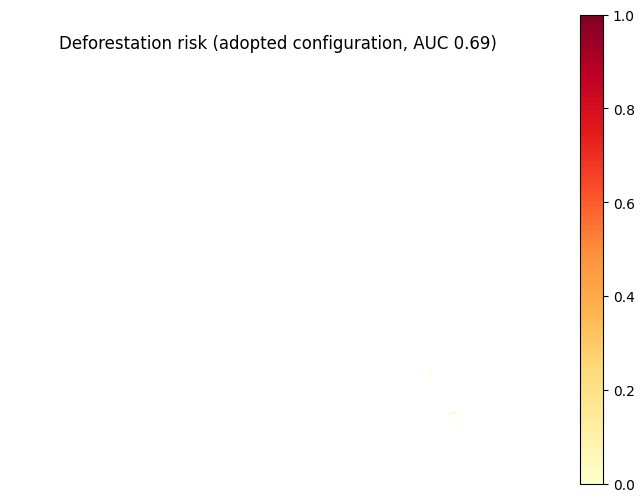

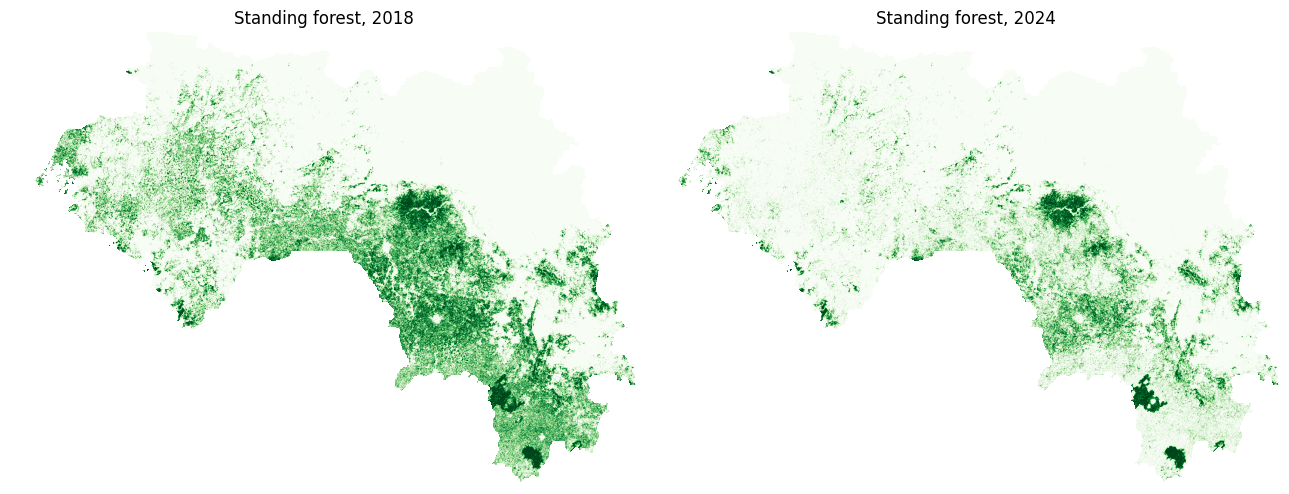

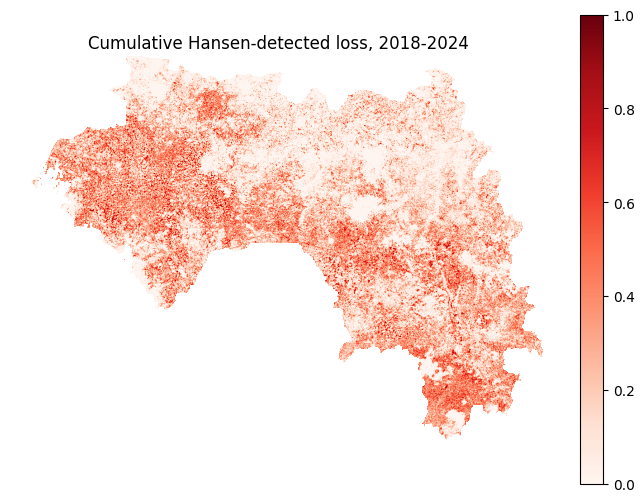

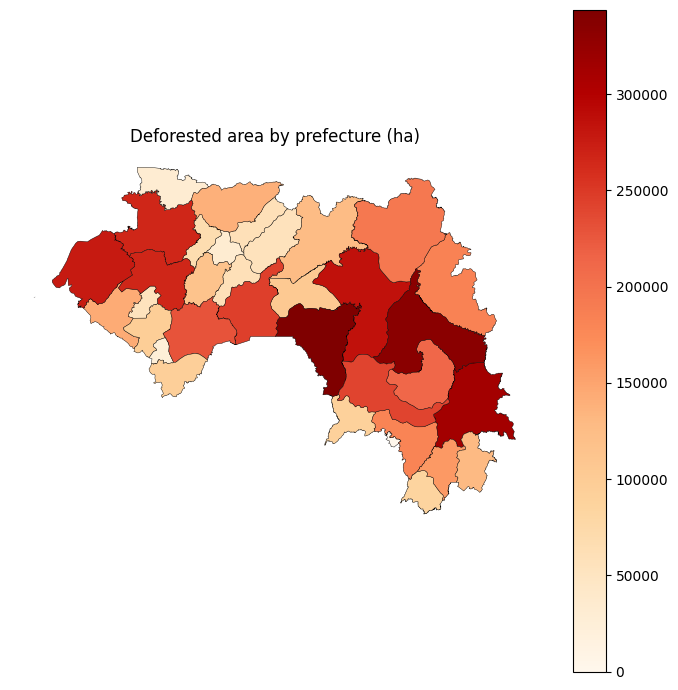

Maps saved to c:\Users\ASUS\Guinea_Project\Land Use-Deforestation\analysis_outputs\maps
    map1_risk.png
    map2_forest_cover_change.png
    map3_cumulative_loss.png
    map4_zonal_choropleth.png


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

MAP_DIR = os.path.join(OUT_DIR, "maps")
os.makedirs(MAP_DIR, exist_ok=True)

def plot_raster_map(array, title, cmap, out_name, vmin=None, vmax=None, mask=None):
    fig, ax = plt.subplots(figsize=(7, 7))
    plotted = np.where(mask, array, np.nan) if mask is not None else array
    im = ax.imshow(plotted, cmap=cmap, vmin=vmin, vmax=vmax)
    ax.set_title(title)
    ax.axis("off")
    plt.colorbar(im, ax=ax, shrink=0.7)
    plt.tight_layout()
    plt.savefig(os.path.join(MAP_DIR, out_name), dpi=150, bbox_inches="tight")
    plt.show()

# --- Map 1: deforestation risk map (the adopted, hold-out-validated configuration) ---
if "risk_map" in defo:
    plot_raster_map(defo["risk_map"], "Deforestation risk (adopted configuration, AUC 0.69)",
                    cmap="YlOrRd", out_name="map1_risk.png", vmin=0, vmax=1, mask=boundary_mask)

# --- Map 2: forest cover, 2018 vs 2024 (side by side) ---
fig, axes = plt.subplots(1, 2, figsize=(13, 7))
for ax, yr in zip(axes, [min(defo["forest_by_year"].keys()), max(defo["forest_by_year"].keys())]):
    plotted = np.where(boundary_mask, defo["forest_by_year"][yr].astype(float), np.nan)
    ax.imshow(plotted, cmap="Greens", vmin=0, vmax=1)
    ax.set_title(f"Standing forest, {yr}")
    ax.axis("off")
plt.tight_layout()
plt.savefig(os.path.join(MAP_DIR, "map2_forest_cover_change.png"), dpi=150, bbox_inches="tight")
plt.show()

# --- Map 3: Hansen-detected loss, cumulative over the whole window ---
plot_raster_map(defo["loss_window_mask"].astype(float),
                f"Cumulative Hansen-detected loss, {min(ANALYSIS_YEARS)}-{max(ANALYSIS_YEARS)}",
                cmap="Reds", out_name="map3_cumulative_loss.png", vmin=0, vmax=1, mask=boundary_mask)

# --- Map 4: per-prefecture choropleth (real polygons, not a bar chart) ---
fig, ax = plt.subplots(figsize=(7, 7))
zonal_geo = zones_gdf.merge(zonal, left_on="name", right_on="zone", how="left")
zonal_geo.plot(column="loss_ha", cmap="OrRd", legend=True, ax=ax,
              edgecolor="black", linewidth=0.3, missing_kwds={"color": "lightgrey"})
ax.set_title("Deforested area by prefecture (ha)")
ax.axis("off")
plt.tight_layout()
plt.savefig(os.path.join(MAP_DIR, "map4_zonal_choropleth.png"), dpi=150, bbox_inches="tight")
plt.show()

print("Maps saved to", MAP_DIR)
for f in sorted(os.listdir(MAP_DIR)):
    print("   ", f)


## 19. Export maps as GeoTIFF (and the choropleth as a proper vector file)

PNGs from Section 18 are for embedding in the report document -- they have no georeferencing
at all, can't be opened in QGIS/ArcGIS, and can't be used for anything downstream. GeoTIFF
preserves the real CRS and transform from REF_PROFILE. The choropleth is fundamentally polygon
data (per-prefecture values), not a raster -- exported as GeoPackage instead, which is the
correct format for that, not forced into a raster it was never meant to be.

In [ ]:
import rasterio
from rasterio.crs import CRS

GEOTIFF_DIR = os.path.join(OUT_DIR, "maps_geotiff")
os.makedirs(GEOTIFF_DIR, exist_ok=True)

def write_geotiff(array, out_name, dtype="float32", nodata=None):
    profile = {
        "driver": "GTiff", "height": REF_PROFILE["height"], "width": REF_PROFILE["width"],
        "count": 1, "dtype": dtype, "crs": REF_PROFILE["crs"], "transform": REF_PROFILE["transform"],
        "nodata": nodata, "compress": "lzw",
    }
    out_path = os.path.join(GEOTIFF_DIR, out_name)
    with rasterio.open(out_path, "w", **profile) as dst:
        dst.write(array.astype(dtype), 1)
    return out_path

# --- Risk map (adopted configuration), masked to Guinea, nodata outside ---
if "risk_map" in defo:
    risk_masked = np.where(boundary_mask, defo["risk_map"], -9999).astype("float32")
    p = write_geotiff(risk_masked, "risk_map.tif", dtype="float32", nodata=-9999)
    print("Wrote", p)

# --- Forest cover, each year (boolean -> uint8, 1=forest/0=not, 255=outside Guinea) ---
for yr, mask_arr in defo["forest_by_year"].items():
    arr = np.where(boundary_mask, mask_arr.astype("uint8"), 255)
    p = write_geotiff(arr, f"forest_cover_{yr}.tif", dtype="uint8", nodata=255)
    print("Wrote", p)

# --- Cumulative Hansen-detected loss over the whole window ---
loss_arr = np.where(boundary_mask, defo["loss_window_mask"].astype("uint8"), 255)
p = write_geotiff(loss_arr, f"cumulative_loss_{min(ANALYSIS_YEARS)}_{max(ANALYSIS_YEARS)}.tif",
                  dtype="uint8", nodata=255)
print("Wrote", p)

print(f"\nAll GeoTIFFs written to {GEOTIFF_DIR}, CRS={REF_PROFILE['crs']}")

# --- Zonal choropleth: proper vector format (GeoPackage), not forced into a raster ---
VECTOR_DIR = os.path.join(OUT_DIR, "maps_vector")
os.makedirs(VECTOR_DIR, exist_ok=True)
zonal_geo_export = zones_gdf.merge(zonal, left_on="name", right_on="zone", how="left")
gpkg_path = os.path.join(VECTOR_DIR, "zonal_deforestation.gpkg")
zonal_geo_export.to_file(gpkg_path, driver="GPKG", layer="zonal_deforestation")
print(f"\nWrote {gpkg_path} (open in QGIS: this is real per-prefecture polygon data with loss_ha attribute)")


Wrote c:\Users\ASUS\Guinea_Project\Land Use-Deforestation\analysis_outputs\maps_geotiff\risk_map.tif
Wrote c:\Users\ASUS\Guinea_Project\Land Use-Deforestation\analysis_outputs\maps_geotiff\forest_cover_2018.tif
Wrote c:\Users\ASUS\Guinea_Project\Land Use-Deforestation\analysis_outputs\maps_geotiff\forest_cover_2019.tif
Wrote c:\Users\ASUS\Guinea_Project\Land Use-Deforestation\analysis_outputs\maps_geotiff\forest_cover_2020.tif
Wrote c:\Users\ASUS\Guinea_Project\Land Use-Deforestation\analysis_outputs\maps_geotiff\forest_cover_2021.tif
Wrote c:\Users\ASUS\Guinea_Project\Land Use-Deforestation\analysis_outputs\maps_geotiff\forest_cover_2022.tif
Wrote c:\Users\ASUS\Guinea_Project\Land Use-Deforestation\analysis_outputs\maps_geotiff\forest_cover_2023.tif
Wrote c:\Users\ASUS\Guinea_Project\Land Use-Deforestation\analysis_outputs\maps_geotiff\forest_cover_2024.tif
Wrote c:\Users\ASUS\Guinea_Project\Land Use-Deforestation\analysis_outputs\maps_geotiff\cumulative_loss_2018_2024.tif

All GeoTIF

INFO pyogrio._io: Created 34 records



Wrote c:\Users\ASUS\Guinea_Project\Land Use-Deforestation\analysis_outputs\maps_vector\zonal_deforestation.gpkg (open in QGIS: this is real per-prefecture polygon data with loss_ha attribute)


## 20. Clean Table 1: raw single-period matrix (bypassing the non-linear fitting entirely)

Calls calculate_transition_matrix directly on two raw observed maps -- no fitting, no
aggregation across periods, nothing that could introduce the artifact found in Section 20's
predecessor. Using 2022->2024 (the most recent, most policy-relevant period) as the headline;
change to 2018->2020 if you'd rather report the earliest instead.

In [ ]:
t_2022 = next(t["file"] for t in target_files if t["year"] == 2022)
t_2024 = next(t["file"] for t in target_files if t["year"] == 2024)

prob_matrix_clean, counts_matrix_clean, _ = change_analysis.calculate_transition_matrix(t_2022, t_2024)

# Drop class 10 ("Clouds" in ESRI's scheme -- a no-data/cloud-masked code, not a real land-cover
# class) before reporting -- confirmed present in earlier matrices at negligible volume, but it
# shouldn't sit in a headline table as if it were a real class.
CLOUDS_CODE = 10
if CLOUDS_CODE in counts_matrix_clean.index:
    print(f"Dropping class {CLOUDS_CODE} (Clouds, no-data code): "
          f"{int(counts_matrix_clean.loc[CLOUDS_CODE].sum() + counts_matrix_clean[CLOUDS_CODE].sum())} px total, "
          f"negligible relative to the full matrix.")
    counts_matrix_clean = counts_matrix_clean.drop(index=CLOUDS_CODE, errors="ignore").drop(columns=CLOUDS_CODE, errors="ignore")
    prob_matrix_clean = prob_matrix_clean.drop(index=CLOUDS_CODE, errors="ignore").drop(columns=CLOUDS_CODE, errors="ignore")

print("\nTable 1 (clean, raw 2022->2024, pixel counts):")
print(counts_matrix_clean.rename(index=CLASS_NAMES, columns=CLASS_NAMES).to_string())

t2r = counts_matrix_clean.loc[2, 11] if 2 in counts_matrix_clean.index and 11 in counts_matrix_clean.columns else 0
r2t = counts_matrix_clean.loc[11, 2] if 11 in counts_matrix_clean.index and 2 in counts_matrix_clean.columns else 0
print(f"\nTrees->Rangeland: {t2r:,.0f} px | Rangeland->Trees: {r2t:,.0f} px")
print(f"Net direction: {'LOSS (Trees shrinking)' if t2r > r2t else 'GAIN (Trees growing)'}")
print("This should match the expected LOSS direction, consistent with Hansen and every prior")
print("established result -- confirming the non-linear fitted matrix, not the raw data, was the issue.")


INFO landuse_tool.change_analysis: Valid pixels: 7057679 / 8414692
INFO landuse_tool.change_analysis: Found 7 land cover classes: [1, 2, 4, 5, 7, 8, 11]
INFO landuse_tool.change_analysis: Transition matrix:
          1         2         4         5         7         8         11
1   0.981688  0.004491  0.002823  0.000533  0.000113  0.001712  0.008640
2   0.000254  0.902618  0.000592  0.001190  0.000573  0.000001  0.094771
4   0.010938  0.051186  0.893407  0.006053  0.000629  0.000108  0.037680
5   0.001699  0.056018  0.014174  0.670723  0.007055  0.000129  0.250202
7   0.000315  0.022324  0.000718  0.002910  0.895448  0.000189  0.078096
8   0.210356  0.001618  0.009709  0.009709  0.005663  0.654531  0.108414
11  0.000281  0.114071  0.000810  0.009988  0.002243  0.000017  0.872590



Table 1 (clean, raw 2022->2024, pixel counts):
                     Water    Trees  Flooded Vegetation  Crops  Built Area  Bare Ground  Rangeland
Water               200653      918                 577    109          23          350       1766
Trees                 1017  3607038                2367   4755        2290            5     378725
Flooded Vegetation     609     2850               49744    337          35            6       2098
Crops                  105     3462                 876  41452         436            8      15463
Built Area              25     1772                  57    231       71078           15       6199
Bare Ground            260        2                  12     12           7          809        134
Rangeland              748   303313                2154  26559        5963           46    2320209

Trees->Rangeland: 378,725 px | Rangeland->Trees: 303,313 px
Net direction: LOSS (Trees shrinking)
This should match the expected LOSS direction, consistent wit

## 21. Oil (palm) price: test against all 3 historical splits before deciding to modify scripts

Same standard dist_forest_edge's exclusion had to meet before becoming a script-level default.
One split showing improvement isn't enough on its own -- reusing risk_holdout_results' already-
computed driver_stack_cal/test for each split (Section 8b), no re-fetching needed.

In [ ]:
oil_palm_results = {}
for split_label, split_data in risk_holdout_results.items():
    stack_cal = dict(split_data["driver_stack_cal"]); stack_cal["commodity_price"] = price_surface
    stack_test = dict(split_data["driver_stack_test"]); stack_test["commodity_price"] = price_surface

    X, y, names = DR.sample_training(split_data["loss_window_cal"], split_data["stable_forest_cal"],
                                     stack_cal, samples_per_class=dcfg.DEFOR_PARAMS["samples_per_class"])
    model, cv = DR.fit_risk_model(X, y, model_type=dcfg.DEFOR_PARAMS["driver_model"])
    risk = DR.predict_risk_map(model, stack_test, names, split_data["forest_test_start"])
    auc = validation.risk_map_auc(risk, split_data["observed_loss_test"], split_data["forest_test_start"])

    baseline_split_auc = split_data["auc"]["auc"]
    oil_palm_results[split_label] = {"baseline_auc": baseline_split_auc, "with_oil_palm_auc": auc["auc"]}
    delta = auc["auc"] - baseline_split_auc
    print(f"{split_label}: baseline {baseline_split_auc:.4f} -> +Oil(palm) {auc['auc']:.4f} "
          f"(delta {delta:+.4f}) {'IMPROVED' if delta > 0 else 'no improvement'}")

n_improved = sum(1 for r in oil_palm_results.values() if r["with_oil_palm_auc"] > r["baseline_auc"])
print(f"\nImproved on {n_improved}/3 splits.")
if n_improved == 3:
    print("Confirmed stable across all 3 splits -- same bar dist_forest_edge's exclusion met.")
    print("Justified to modify the scripts now (register WFP price fetch as a standard predictor,")
    print("add to the adopted driver stack in drivers.py/pipeline.py).")
elif n_improved >= 1:
    print("Improved on SOME but not all splits -- mixed evidence, same situation NDVI/burned area")
    print("were in before being rejected, just less severe. Recommend NOT modifying scripts yet;")
    print("report as 'tested, inconsistent across periods' rather than adopting.")
else:
    print("Did not hold up outside the original split -- the +0.008 was likely split-specific")
    print("noise, not a real signal. Recommend NOT modifying scripts; report as tested and rejected,")
    print("same treatment as NDVI and burned area.")


2015-2018: baseline 0.6891 -> +Oil(palm) 0.6986 (delta +0.0095) IMPROVED
2013-2016: baseline 0.6600 -> +Oil(palm) 0.6659 (delta +0.0059) IMPROVED
2010-2013: baseline 0.5642 -> +Oil(palm) 0.5680 (delta +0.0038) IMPROVED

Improved on 3/3 splits.
Confirmed stable across all 3 splits -- same bar dist_forest_edge's exclusion met.
Justified to modify the scripts now (register WFP price fetch as a standard predictor,
add to the adopted driver stack in drivers.py/pipeline.py).
